# 👁️ Dynamic Foveated Diffusion
### *Biologically-Inspired Generative Vision*
> **intro to NeuroAI Final Project** | Roi Maman & Roy Carmel | 2026
 
---

# 🔵1) intro

Biological vision optimizes metabolic bandwidth by restricting peak acuity to the fovea while aggressively compressing peripheral input. Building on this principle, the paper "Foveated Diffusion: Efficient Spatially Adaptive Image and Video Generation" demonstrated that diffusion models can drastically reduce sequence length and latency by processing a designated foveal region at full resolution while downsampling the surrounding periphery.

While the original work relies on rigid, predefined spatial masks, biological visual attention is inherently dynamic. We extend this paradigm by introducing an autonomous, model-intrinsic foveation mechanism: rather than imposing manual masks, our pipeline extracts spatial saliency on the fly from early denoising activations (analogous to V1 cortical receptive fields). This should allows the model to dynamically detect semantically critical focal zones and allocate full-resolution tokens adaptively, achieving biologically grounded compute allocation without manual intervention.

# 🔵2) ?

# 🔵3) implementing the base denoising loop using PixArt-Alpha

### Baseline Implementation: Manual PixArt-Alpha Denoising Loop

Before introducing token-level sequence compression and foveation, we must establish a transparent, uncompressed baseline. Standard high-level interfaces (such as Hugging Face's `DiffusionPipeline`) abstract away token projections and spatial tensor layouts into a "black box," preventing any direct intervention in patch manipulation. 

#### Model Selection: Why PixArt-Alpha?
Selecting the appropriate architectural backbone is critical for evaluating foveated generative rendering under hardware constraints:
* **The Necessity of a Transformer Backbone:** Standard Latent Diffusion Models like Stable Diffusion (v1.5 / SDXL) rely on convolutional U-Net backbones. Convolutions strictly enforce rigid, continuous 2D spatial feature maps ($C \times H \times W$), making dynamic token pruning or asymmetric mixed-resolution representations structurally incompatible without heavy zero-padding or severe architectural degradation. In contrast, **Diffusion Transformers (DiT)** patchify the latent space into discrete, flattened sequences of visual tokens. Because Transformer self-attention naturally processes flexible sequence lengths rather than fixed spatial grids, DiTs allow us to prune, downsample, and recombine spatial patches arbitrarily—translating peripheral compression directly into quadratic $O(N^2)$ self-attention compute and latency savings.
* **PixArt-Alpha vs. Frontier Baselines (FLUX):** The original foveation research benchmarked heavily against frontier architectures like FLUX (\~4B parameters). While powerful, training or adapting 4B-parameter models requires datacenter-scale compute and multi-GPU clusters well beyond what we had access to. PixArt-Alpha (~600M parameters) provides the optimal experimental testbed: it retains the true Transformer token mechanics and high-capacity T5 text conditioning of modern DiTs, yet remains computationally tractable for localized LoRA fine-tuning and sub-second inference on an 8GB VRAM GPU.

#### Objectives of this Baseline
In this section, we construct a fully exposed, manual denoising loop for PixArt-Alpha to achieve two goals:
1. **Validation Baseline:** Establishing ground-truth visual fidelity, execution latency, and token throughput at full sequence length (100% tokens).
2. **Structural Transparency:** Exposing every low-level component—T5 text projection, adaptive layer-norm (adaLN) timestep conditioning, Classifier-Free Guidance (CFG), multi-step ODE scheduling, and tiled VAE decoding—providing the necessary hooks to inject custom foveated sequence manipulation.

### 🟠3.1) first step, tokenizing the prompt, and deleating the model from memory

#### Why Decouple Text Encoding? (VRAM Constraints & Memory Isolation)

PixArt-Alpha relies on the massive **T5-v1.1-XXL** model as its text encoder (~4.3B parameters), requiring nearly 9–10 GB of memory in FP16/BF16. Attempting to keep both the T5 encoder and the 600M-parameter Transformer model in GPU memory simultaneously triggers immediate Out-Of-Memory (OOM) errors on consumer-grade hardware (such as an 8GB VRAM GPU).

To resolve this bottleneck, we decouple the pipeline into a sequential two-stage execution:
* **Pre-computation:** We tokenize the text prompt and pass it through T5 once to extract the semantic embeddings (`prompt_embeds`) and attention masks (`prompt_attention_mask`).
* **Memory Flushing:** Once the embeddings are transferred to RAM, the T5 model and tokenizer are explicitly deleted, followed by manual garbage collection (`gc.collect()`) and CUDA cache clearing (`torch.cuda.empty_cache()`). This frees 100% of the VRAM for the downstream DiT and VAE architectures.

In [1]:
import os
os.environ["_CHECK_PEFT"] = "0"


import torch
import PIL
import numpy as np
import gc
from tqdm.auto import tqdm
from diffusers import PixArtAlphaPipeline, Transformer2DModel, AutoencoderKL
from transformers import T5EncoderModel
from IPython.display import display

print("Loading T5 Text Encoder temporarily...")
model_id = "PixArt-alpha/PixArt-XL-2-512x512"

# Load only the encoder to memory
text_encoder = T5EncoderModel.from_pretrained(
    model_id, 
    subfolder="text_encoder", 
    torch_dtype=torch.float16
).to("cuda")

# Load its tokenizer
from transformers import T5Tokenizer
tokenizer = T5Tokenizer.from_pretrained(model_id, subfolder="tokenizer")

prompt = "a small dog with a mexican hat"
negative_prompt = ""

device = torch.device("cuda")
max_sequence_length = 120  # PixArt's prompt length

def encode_text(prompt, negative_prompt):
    text_inputs = tokenizer(
        prompt,
        padding="max_length",
        max_length=max_sequence_length,
        truncation=True,
        return_tensors="pt",
    )
    text_input_ids = text_inputs.input_ids.to(device)
    prompt_attention_mask = text_inputs.attention_mask.to(device)
    prompt_embeds = text_encoder(text_input_ids, attention_mask=prompt_attention_mask)[0]

    uncond_inputs = tokenizer(
        negative_prompt,
        padding="max_length",
        max_length=max_sequence_length,
        truncation=True,
        return_tensors="pt",
    )
    uncond_input_ids = uncond_inputs.input_ids.to(device)
    negative_attention_mask = uncond_inputs.attention_mask.to(device)
    negative_prompt_embeds = text_encoder(uncond_input_ids, attention_mask=negative_attention_mask)[0]

    return prompt_embeds, prompt_attention_mask, negative_prompt_embeds, negative_attention_mask

print("Encoding prompt...")
with torch.no_grad():
    p_embeds, p_mask, n_embeds, n_mask = encode_text(prompt, negative_prompt)

# [negative, positive]: the order the CFG chunk(2) expects
prompt_embeds = torch.cat([n_embeds, p_embeds], dim=0)
prompt_attention_mask = torch.cat([n_mask, p_mask], dim=0)

# free T5 before the transformer is loaded
print("Unloading T5 from VRAM...")
del text_encoder
del tokenizer
torch.cuda.empty_cache()
gc.collect()
print(f"VRAM after clearing T5: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

Loading T5 Text Encoder temporarily...


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Encoding prompt...
Unloading T5 from VRAM...
VRAM after clearing T5: 0.01 GB


### 🟠3.2) loading the model, and running it on the pre-made embeddings

#### Manual Diffusion Inference on Pre-computed Embeddings

With GPU memory cleared, we load the **Transformer2DModel (DiT)** and the **AutoencoderKL (VAE)** to execute the manual denoising loop:

1. **Latent Noise Initialization:** We sample standard Gaussian noise scaled by the scheduler's initial noise standard deviation (`init_noise_sigma`).
2. **Classifier-Free Guidance (CFG):** At each discrete timestep $t$, the latent batch is duplicated (`torch.cat([x] * 2)`) to compute conditional and unconditional predictions in a single forward pass, combining them via:
   $$\epsilon_\theta = \epsilon_{\text{uncond}} + s \cdot (\epsilon_{\text{text}} - \epsilon_{\text{uncond}})$$
3. **Multi-step Scheduling:** We feed the predicted velocity/noise into `DPMSolverMultistepScheduler` to compute the reverse-time ODE trajectory across 20 timesteps.
4. **Full-Resolution VAE Decoding:** The final denoised latent tensor is scaled by the VAE scaling factor and decoded back to RGB pixel space, establishing our ground-truth fidelity and timing benchmark.

Loading Transformer and VAE to GPU...


Some weights of the model checkpoint at PixArt-alpha/PixArt-XL-2-512x512 were not used when initializing PixArtTransformer2DModel: 
 ['caption_projection.y_embedding']


Running Denoising Loop on GPU...


  0%|          | 0/20 [00:00<?, ?it/s]

Decoding latents to image...


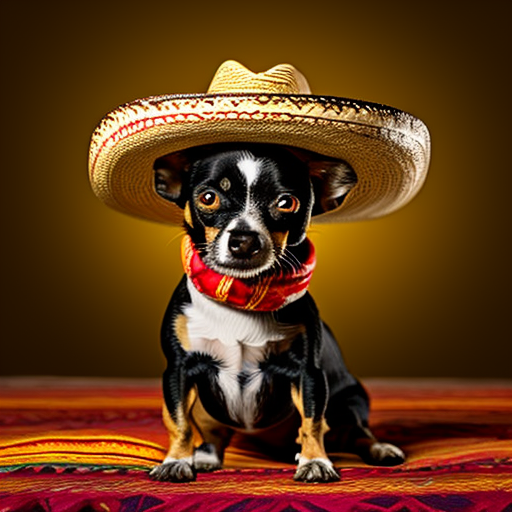

In [2]:
print("Loading Transformer and VAE to GPU...")
transformer = Transformer2DModel.from_pretrained(
    model_id, 
    subfolder="transformer", 
    torch_dtype=torch.float16
).to("cuda")

vae = AutoencoderKL.from_pretrained(
    model_id, 
    subfolder="vae", 
    torch_dtype=torch.float16
).to("cuda")

# standard PixArt scheduler
from diffusers import DPMSolverMultistepScheduler
scheduler = DPMSolverMultistepScheduler.from_pretrained(model_id, subfolder="scheduler")


# manual denoising loop
def run_diffusion_loop(transformer, vae, scheduler, prompt_embeds, prompt_attention_mask, seed=42, steps=20, guidance_scale=4.5, height=512, width=512):
    generator = torch.Generator(device=device).manual_seed(seed)
    
    scheduler.set_timesteps(steps)
    latents = torch.randn(
        (1, 4, height // 8, width // 8), 
        generator=generator, 
        device=device, 
        dtype=torch.float16
    )
    latents = latents * scheduler.init_noise_sigma

    resolution = torch.tensor([height, width], dtype=torch.float16, device=device).repeat(2, 1)
    aspect_ratio = torch.tensor([float(height / width)], dtype=torch.float16, device=device).repeat(2, 1)
    added_cond_kwargs = {"resolution": resolution, "aspect_ratio": aspect_ratio}

    print("Running Denoising Loop on GPU...")
    for i, t in enumerate(tqdm(scheduler.timesteps)):
        latent_model_input = torch.cat([latents] * 2)
        
        t = t.to(device)
        latent_model_input = scheduler.scale_model_input(latent_model_input, t)

        t_val = t.item() if isinstance(t, torch.Tensor) else t
        t_batch = torch.tensor([t_val, t_val], device=device)

        with torch.no_grad():
            noise_pred = transformer(
                latent_model_input,
                encoder_hidden_states=prompt_embeds,
                encoder_attention_mask=prompt_attention_mask,
                timestep=t_batch,
                added_cond_kwargs=added_cond_kwargs,
                return_dict=False,
            )[0]

        if noise_pred.shape[1] == 8:
            noise_pred, _ = noise_pred.chunk(2, dim=1)

        noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)
        noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)

        latents = scheduler.step(noise_pred, t, latents).prev_sample
        latents = latents.to(device)

    # decode the final latents with the VAE
    print("Decoding latents to image...")
    with torch.no_grad():
        latents = (1 / vae.config.scaling_factor) * latents
        image = vae.decode(latents.to(vae.dtype)).sample

    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).float().numpy()
    final_image = PIL.Image.fromarray((image[0] * 255).round().astype("uint8"))
    
    return final_image

image = run_diffusion_loop(transformer, vae, scheduler, prompt_embeds, prompt_attention_mask, seed=42, steps=20, guidance_scale=7.5)
display(image)

### 🟠3.3) diagnostic: is `2*pool` of a latent still a valid latent?

Two questions this settles, with numbers instead of arguments.

**Part A (needs only section 3).** The periphery can be built two ways: pool the latent, `2*avg_pool2d(E(x), 2)`, which is what sections 4-6 do, or encode a downsampled image, `E(Down(x))`, which is what the paper does (Eqs. 8-9). Pooling is linear, the VAE encoder is not, so `pool(E(x)) != E(Down(x))` and the pooled version is not a latent of any image. We decode all three against the true bicubic downsample and measure how far off the manifold each one is.

The latent standard deviations also give a direct estimate of the within-block correlation ρ: pooling then scaling by 2 multiplies the std by `sqrt(1 + 3ρ)`, so ρ can be read straight off the ratio. ρ = 0 would mean white content (std preserved exactly, which is why the same `*2` is exactly correct for pure noise); ρ near 1 means smooth content and an inflated signal.

**Part B (skipped unless 4.1-4.3 have been run).** The naive path has no pooling distortion at all: its only pooling is on pure noise, which `2*avg_pool2d` leaves exactly iid. Its failure mechanism is trajectory divergence instead. So we run the naive foveated loop and compare the final peripheral latents against the foveal ones, which act as an in-distribution control since they are the same model on tokens it was trained for.

full-res latent E(x): std 1.026, absmax 5.39
peripheral latent          std   absmax  clipped px  PSNR vs ref
2*pool(E(x)) [ours]      1.794     6.08       48.1%      16.1 dB
pool(E(x))   [no *2]     0.897     3.04       16.1%      18.9 dB
E(Down(x))   [paper]     0.922     4.12        6.0%      22.2 dB

std inflation from the '*2': 1.75x  ->  implied correlation rho = 0.68
(rho=0 would mean white content, where the '*2' is exactly right - as it is for pure noise)


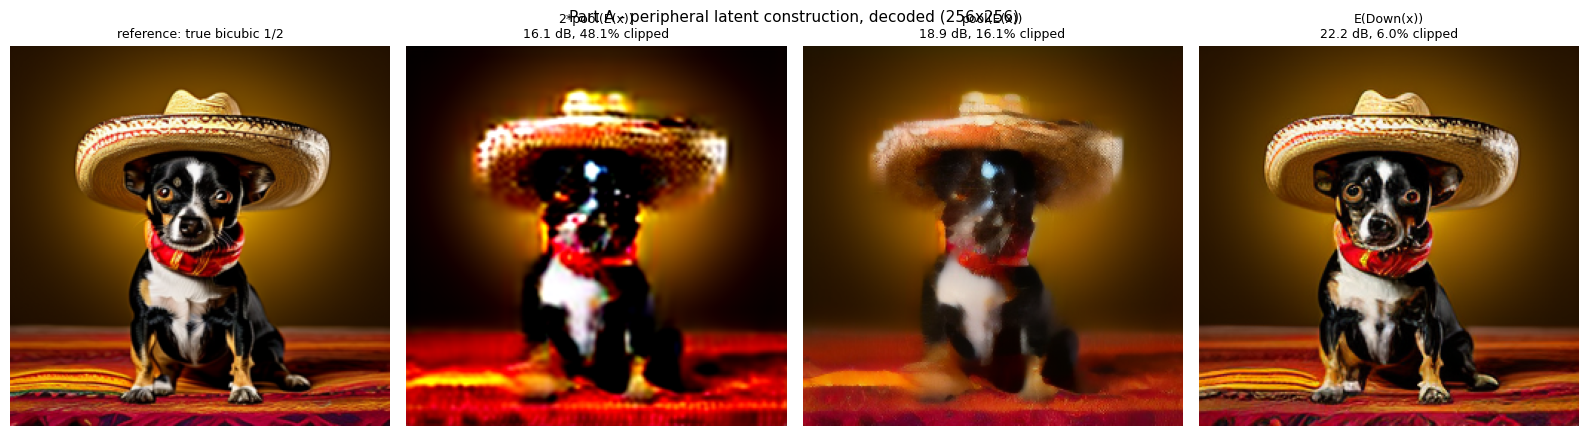

  0%|          | 0/20 [00:00<?, ?it/s]

RuntimeError: mat1 and mat2 must have the same dtype, but got BFloat16 and Half

In [22]:
# Diagnostic: pooled latents vs encoded-downsample latents, and naive-path divergence.
# Part A needs only section 3 (vae + any 512x512 image). Part B self-skips unless 4.1-4.3 have run.

import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt

SF = vae.config.scaling_factor


def _to_latent_input(pil_img):
    """PIL RGB -> (1, 3, H, W) in [-1, 1], the range the VAE encoder expects."""
    arr = np.array(pil_img.convert("RGB"), dtype=np.float32) / 127.5 - 1.0
    return torch.from_numpy(arr).permute(2, 0, 1)[None].to(device=device, dtype=vae.dtype)


@torch.no_grad()
def vae_manifold_test(pil_img):
    x = _to_latent_input(pil_img)

    # reference: the true low-res image, what the periphery should represent
    x_down = F.interpolate(x.float(), scale_factor=0.5, mode="bicubic",
                           antialias=True).clamp(-1, 1)

    z_hi = vae.encode(x).latent_dist.mean * SF                       # (1, 4, 64, 64)
    z_hi_std = z_hi.float().std().item()

    variants = {
        "2*pool(E(x)) [ours]":   F.avg_pool2d(z_hi.float(), 2) * 2,
        "pool(E(x))   [no *2]":  F.avg_pool2d(z_hi.float(), 2),
        "E(Down(x))   [paper]":  vae.encode(x_down.to(vae.dtype)).latent_dist.mean.float() * SF,
    }

    ref01 = (x_down / 2 + 0.5).clamp(0, 1)
    rows, panels = [], [(ref01, "reference: true bicubic 1/2")]

    for name, z in variants.items():
        img = vae.decode(z.to(vae.dtype) / SF).sample.float()        # (1, 3, 256, 256), nominally [-1, 1]
        out_of_range = 100 * ((img < -1) | (img > 1)).float().mean().item()
        img01 = (img / 2 + 0.5).clamp(0, 1)                          # what to_pil would actually show
        psnr = (10 * torch.log10(1.0 / F.mse_loss(img01, ref01))).item()

        rows.append((name, z.std().item(), z.abs().max().item(), out_of_range, psnr))
        panels.append((img01, f"{name.split('[')[0].strip()}\n{psnr:.1f} dB, {out_of_range:.1f}% clipped"))

    print(f"full-res latent E(x): std {z_hi_std:.3f}, absmax {z_hi.float().abs().max().item():.2f}")
    print(f"{'peripheral latent':<23}{'std':>7}{'absmax':>9}{'clipped px':>12}{'PSNR vs ref':>13}")
    for name, std, amax, clipped, psnr in rows:
        print(f"{name:<23}{std:>7.3f}{amax:>9.2f}{clipped:>11.1f}%{psnr:>10.1f} dB")

    # pooling then *2 scales std by sqrt(1 + 3*rho); invert to read off the within-block correlation
    ratio = rows[0][1] / z_hi_std
    print(f"\nstd inflation from the '*2': {ratio:.2f}x  ->  implied correlation rho = {(ratio ** 2 - 1) / 3:.2f}")
    print("(rho=0 would mean white content, where the '*2' is exactly right - as it is for pure noise)")

    fig, axes = plt.subplots(1, len(panels), figsize=(4 * len(panels), 4.4))
    for ax, (im, title) in zip(axes, panels):
        ax.imshow(im[0].permute(1, 2, 0).cpu().numpy())
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    plt.suptitle("Part A - peripheral latent construction, decoded (256x256)", fontsize=11)
    plt.tight_layout()
    plt.show()


@torch.no_grad()
def naive_divergence_test(radius=0.25, seed=42, steps=20, guidance_scale=4.5):
    layout = build_layout(make_circular_mask(center=(0.5, 0.5), radius=radius))
    x = run_foveated_loop(layout, prompt_embeds, prompt_attention_mask,
                          seed=seed, steps=steps, guidance_scale=guidance_scale)

    hi = x[:, :layout["n_hi"]].float()     # in-distribution control: ordinary PixArt tokens
    lo = x[:, layout["n_hi"]:].float()     # tokens the pretrained model has never seen

    print(f"\nnaive foveated loop, radius {radius}, token ratio {layout['token_ratio']:.0%}")
    print(f"{'final latents':<14}{'std':>7}{'mean':>8}{'absmax':>9}{'|x|>4':>9}")
    for name, t in (("foveal", hi), ("peripheral", lo)):
        frac = 100 * (t.abs() > 4).float().mean().item()
        print(f"{name:<14}{t.std().item():>7.3f}{t.mean().item():>8.3f}"
              f"{t.abs().max().item():>9.2f}{frac:>8.1f}%")
    print(f"periphery/fovea std ratio: {lo.std().item() / hi.std().item():.2f}"
          "   (>1 means the peripheral trajectory drifted)")
    return layout, x


# ---- Part A ----
_src = image if "image" in globals() else run_diffusion_loop(
    transformer, vae, scheduler, prompt_embeds, prompt_attention_mask,
    seed=42, steps=20, guidance_scale=4.5)
vae_manifold_test(_src)

# ---- Part B (needs 4.1-4.3) ----
if all(k in globals() for k in ("run_foveated_loop", "build_layout", "make_circular_mask")):
    naive_divergence_test()
else:
    print("\nPart B skipped: run sections 4.1-4.3 first, then re-run this cell.")


# 🔵4) Naïve foveated diffusion (training-free mixed-resolution baseline)

The paper's *Naïve Mixed-Resolution Denoising* baseline: the pretrained PixArt denoises a mixed-resolution token sequence, with no training.
- inside the foveation mask: normal high-res tokens (each covers 16x16 pixels)
- outside it: one low-res token per 2x2 block of high-res tokens (covers 32x32 pixels), so 4x fewer tokens in the periphery
- the transformer blocks accept any token sequence; only the patch embedding, the positional embeddings and the unpatchify assume a grid, so we redo those per token. Low-res tokens get PixArt's sin-cos position at the centre of the block they replace (our stand-in for the paper's mixed-resolution RoPE)
- at the end the two parts are decoded separately by the VAE, the periphery is upsampled and the two are blended (Eq. 5-7)

Expected result: scale mismatches / duplicated objects around the fovea boundary (paper Fig. 4-5). Foveated training is what fixes this later.

Uses `transformer`, `vae`, `scheduler`, `prompt_embeds`, `prompt_attention_mask`, `device` and `run_diffusion_loop` from section 3 - run 3.1 and 3.2 first.

### 🟠4.1) foveated tokenization: masks, packing and positions

In [5]:
import time
import torch.nn.functional as F
import matplotlib.pyplot as plt
from diffusers.models.embeddings import get_2d_sincos_pos_embed_from_grid

P = transformer.config.patch_size      # 2 -> one token = 2x2 latent pixels = 16x16 image pixels
C = transformer.config.in_channels     # 4 latent channels
D = transformer.inner_dim              # 1152 hidden size
pe = transformer.pos_embed
POS_SCALE = pe.base_size / pe.height / pe.interpolation_scale   # PixArt's position scaling (=1 for the 512 model)
GRID = pe.height                       # the high-res token grid is GRID x GRID (32x32 for 512x512 images)

def patchify(z):
    """(B, C, H, W) latent grid -> (B, H/P * W/P, P*P*C) tokens, row-major, same layout PixArt uses to unpatchify."""
    B, c, H, W = z.shape
    return z.reshape(B, c, H // P, P, W // P, P).permute(0, 2, 4, 3, 5, 1).reshape(B, (H // P) * (W // P), P * P * c)

def unpatchify(tokens, h, w, c=C):
    """(B, h*w, P*P*c) tokens -> (B, c, h*P, w*P) latent grid."""
    B = tokens.shape[0]
    return tokens.reshape(B, h, w, P, P, c).permute(0, 5, 1, 3, 2, 4).reshape(B, c, h * P, w * P)

def make_circular_mask(center=(0.5, 0.5), radius=0.25, grid=GRID):
    """Circular foveation mask on the high-res token grid. center=(y, x) and radius are fractions of the image size."""
    ys, xs = torch.meshgrid(torch.arange(grid), torch.arange(grid), indexing="ij")
    ys, xs = (ys + 0.5) / grid, (xs + 0.5) / grid
    return (ys - center[0]) ** 2 + (xs - center[1]) ** 2 < radius ** 2

def build_layout(M):
    """
    Foveated token layout from a boolean mask M on the high-res token grid (h x w).
    Inside the fovea we keep every high-res token; outside it, one low-res token replaces each 2x2 block.
    Sequence order: [high-res tokens (row-major) | low-res tokens (row-major)].
    """
    h, w = M.shape
    Mb = M.reshape(h // 2, 2, w // 2, 2).any(dim=3).any(dim=1)     # block grid: True = block is in the fovea
    M = Mb.repeat_interleave(2, 0).repeat_interleave(2, 1)          # snap the mask to whole 2x2 blocks
    hi_idx = M.flatten().nonzero().squeeze(1)
    lo_idx = (~Mb).flatten().nonzero().squeeze(1)

    # token coordinates on the high-res token grid, in (x, y) order like PatchEmbed
    ys, xs = torch.meshgrid(torch.arange(h), torch.arange(w), indexing="ij")
    hi_xy = torch.stack([xs, ys], -1).reshape(-1, 2)[hi_idx].float()
    ys, xs = torch.meshgrid(torch.arange(h // 2), torch.arange(w // 2), indexing="ij")
    lo_xy = torch.stack([xs, ys], -1).reshape(-1, 2)[lo_idx].float() * 2 + 0.5   # centre of the 2x2 block it replaces
    xy = torch.cat([hi_xy, lo_xy]) * POS_SCALE

    # the same sin-cos embedding PixArt uses, just evaluated at our (possibly fractional) positions
    pos = get_2d_sincos_pos_embed_from_grid(D, xy.T.to(device), output_type="pt").float()[None]

    n_hi, n_lo = len(hi_idx), len(lo_idx)
    return dict(M=M, Mb=Mb, hi_idx=hi_idx.to(device), lo_idx=lo_idx.to(device), pos=pos,
                n_hi=n_hi, n_lo=n_lo, h=h, w=w, token_ratio=(n_hi + n_lo) / (h * w))

### 🟠4.2) PixArt forward pass on a foveated token sequence + sanity checks

In [6]:
@torch.no_grad()
def fov_transformer(x, t, layout, prompt_embeds, prompt_attention_mask):
    """
    PixArt forward pass on a packed foveated token sequence.
    x: (B, L, P*P*C) noisy latent patches -> returns the predicted noise, same shape.
    Same as transformer.forward(), except the steps that assume a regular grid
    (patch embedding, positions, unpatchify) are done per token.
    """
    B = x.shape[0]

    # 1. patch embedding: PixArt's conv (kernel = stride = P) is just a linear layer applied to each patch
    W_in = pe.proj.weight.permute(0, 2, 3, 1).reshape(D, P * P * C)   # (p, q, c) order, matches patchify()
    h = (F.linear(x, W_in, pe.proj.bias) + layout["pos"]).to(x.dtype)

    # 2. timestep + text conditioning, as in transformer.forward
    #    (resolution/aspect_ratio are ignored by the 512 model; the 1024 model needs real values here)
    t_emb, t_raw = transformer.adaln_single(t.expand(B), {"resolution": None, "aspect_ratio": None},
                                            batch_size=B, hidden_dtype=h.dtype)
    enc = transformer.caption_projection(prompt_embeds).view(B, -1, D)
    enc_bias = ((1 - prompt_attention_mask.to(h.dtype)) * -10000.0).unsqueeze(1)

    # 3. transformer blocks - these don't care about the grid, any token sequence works
    for block in transformer.transformer_blocks:
        h = block(h, attention_mask=None, encoder_hidden_states=enc, encoder_attention_mask=enc_bias,
                  timestep=t_emb, cross_attention_kwargs=None, class_labels=None)

    # 4. output head, per token
    shift, scale = (transformer.scale_shift_table[None] + t_raw[:, None]).chunk(2, dim=1)
    h = transformer.norm_out(h) * (1 + scale) + shift
    out = transformer.proj_out(h)                                          # (B, L, P*P*8)
    out = out.reshape(B, -1, P * P, transformer.out_channels)[..., :C]    # keep eps, drop the learned-variance channels
    return out.reshape(B, -1, P * P * C)

In [7]:
# sanity checks: with an all-high-res mask the foveated path must reproduce normal PixArt

# 1) positions: our embedding must equal PixArt's own table
full_layout = build_layout(torch.ones(GRID, GRID, dtype=torch.bool))
print("pos-embed max diff :", (full_layout["pos"] - pe.pos_embed).abs().max().item())    # expect ~0

# 2) forward pass: fov_transformer must match transformer(...)
scheduler.set_timesteps(20)
t = scheduler.timesteps[5].to(device)
z = torch.randn(2, C, GRID * P, GRID * P, device=device, dtype=torch.float16)
with torch.no_grad():
    ref = transformer(z, encoder_hidden_states=prompt_embeds, encoder_attention_mask=prompt_attention_mask,
                      timestep=t.expand(2), added_cond_kwargs={"resolution": None, "aspect_ratio": None},
                      return_dict=False)[0][:, :C]
out = unpatchify(fov_transformer(patchify(z), t, full_layout, prompt_embeds, prompt_attention_mask), GRID, GRID)
print("forward max diff   :", (ref - out).abs().max().item(), "| mean |eps|:", ref.abs().mean().item())  # expect small (fp16 noise, ~1e-2 or less)

pos-embed max diff : 0.0
forward max diff   : 0.0029296875 | mean |eps|: 0.79248046875


### 🟠4.3) foveated denoising loop and decoding
Same loop as 3.2, but the latent is a packed sequence of L patches instead of a 64x64 grid.

In [8]:
def to_pil(img):
    img = (img.float() / 2 + 0.5).clamp(0, 1)[0].permute(1, 2, 0).cpu().numpy()
    return PIL.Image.fromarray((img * 255).round().astype("uint8"))

def foveated_noise(layout, seed):
    """
    Initial noise for the packed sequence, taken from the SAME full-res noise run_diffusion_loop draws for this seed,
    so full-res and foveated runs are directly comparable. Low-res noise = 2x2 average * 2 (keeps unit variance).
    """
    g = torch.Generator(device=device).manual_seed(seed)
    z = torch.randn((1, C, layout["h"] * P, layout["w"] * P), generator=g, device=device, dtype=torch.float16)
    z_lo = (F.avg_pool2d(z.float(), 2) * 2).half()
    return torch.cat([patchify(z)[:, layout["hi_idx"]], patchify(z_lo)[:, layout["lo_idx"]]], dim=1)

def run_foveated_loop(layout, prompt_embeds, prompt_attention_mask, seed=42, steps=20,
                      guidance_scale=4.5, guidance_scale_lo=None, rescale_lo=False):
    """
    guidance_scale_lo : separate CFG weight for the peripheral tokens. None = same as the fovea,
                        which reproduces the original behaviour exactly.
    rescale_lo        : renormalise the peripheral eps to the std of its own eps_text (Lin et al.).
                        Removes CFG magnitude inflation without pushing the prompt differently on
                        the two sides of the seam, so it should not add a contrast step at the border.
    """
    scheduler.set_timesteps(steps)
    x = foveated_noise(layout, seed) * scheduler.init_noise_sigma      # (1, L, P*P*C) instead of (1, 4, 64, 64)
    n_hi = layout["n_hi"]

    # CFG is elementwise on the token axis, so the weight can just be a per-token vector
    g = torch.full((1, x.shape[1], 1), float(guidance_scale), device=device, dtype=x.dtype)
    if guidance_scale_lo is not None:
        g[:, n_hi:] = float(guidance_scale_lo)

    for t in tqdm(scheduler.timesteps):
        t = t.to(device)
        x_in = scheduler.scale_model_input(torch.cat([x] * 2), t)
        eps_uncond, eps_text = fov_transformer(x_in, t, layout, prompt_embeds, prompt_attention_mask).chunk(2)
        eps = eps_uncond + g * (eps_text - eps_uncond)
        if rescale_lo:
            s = eps_text[:, n_hi:].float().std() / (eps[:, n_hi:].float().std() + 1e-6)
            eps[:, n_hi:] = (eps[:, n_hi:].float() * s).to(eps.dtype)
        x = scheduler.step(eps, t, x).prev_sample                     # scheduler math is elementwise, the shape doesn't matter
    return x

@torch.no_grad()
def decode_foveated(x, layout):
    """Split -> decode each part with the VAE -> upsample the periphery -> blend with the mask (paper Eq. 5-7)."""
    h, w, n_hi = layout["h"], layout["w"], layout["n_hi"]
    hi = torch.zeros(1, h * w, P * P * C, device=device, dtype=x.dtype)
    lo = torch.zeros(1, (h // 2) * (w // 2), P * P * C, device=device, dtype=x.dtype)
    hi[:, layout["hi_idx"]] = x[:, :n_hi]
    lo[:, layout["lo_idx"]] = x[:, n_hi:]
    z_hi, z_lo = unpatchify(hi, h, w), unpatchify(lo, h // 2, w // 2)          # (1,4,64,64) and (1,4,32,32)

    # fill each grid's empty part from the other one, so the VAE decoder doesn't see zeros next to the boundary
    m_hi = layout["M"].repeat_interleave(P, 0).repeat_interleave(P, 1).to(device)
    m_lo = layout["Mb"].repeat_interleave(P, 0).repeat_interleave(P, 1).to(device)
    z_lo = torch.where(m_lo, F.avg_pool2d(z_hi.float(), 2).to(z_hi.dtype), z_lo)
    z_hi = torch.where(m_hi, z_hi, F.interpolate(z_lo.float(), scale_factor=2, mode="nearest").to(z_hi.dtype))

    img_hi = vae.decode(z_hi / vae.config.scaling_factor).sample                  # (1,3,512,512)
    img_lo = vae.decode(z_lo / vae.config.scaling_factor).sample                  # (1,3,256,256)
    img_lo_up = F.interpolate(img_lo.float(), scale_factor=2, mode="bicubic")
    m_px = layout["M"].float().repeat_interleave(P * 8, 0).repeat_interleave(P * 8, 1).to(device)
    img = m_px * img_hi.float() + (1 - m_px) * img_lo_up
    return to_pil(img), to_pil(img_hi), to_pil(img_lo)

def draw_fovea_border(pil_img, layout, color=(255, 255, 255)):
    """White outline around the high-res region, like the figures in the paper."""
    m = F.interpolate(layout["M"].float()[None, None], size=pil_img.size[::-1], mode="nearest")
    ring = (F.max_pool2d(m, 5, stride=1, padding=2) - m)[0, 0] > 0
    arr = np.array(pil_img)
    arr[ring.numpy()] = color
    return PIL.Image.fromarray(arr)

### 🟠4.4) full high-res vs naive foveated (same prompt, same seed)
At 512x512 there are only 1024 tokens, so attention is not the bottleneck and the speedup is small; the point here is the image quality comparison.

tokens: 240 high-res + 196 low-res = 436 / 1024  (token ratio 43%)
Running Denoising Loop on GPU...


  0%|          | 0/20 [00:00<?, ?it/s]

Decoding latents to image...


  0%|          | 0/20 [00:00<?, ?it/s]

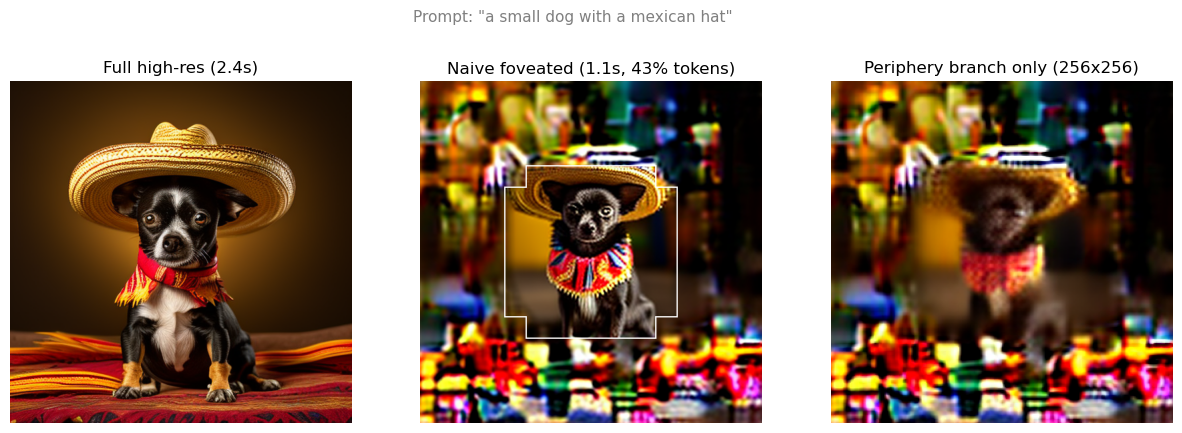

In [9]:
SEED, STEPS, GUIDANCE = 42, 20, 4.5

layout = build_layout(make_circular_mask(center=(0.5, 0.5), radius=0.25))
print(f"tokens: {layout['n_hi']} high-res + {layout['n_lo']} low-res = {layout['n_hi'] + layout['n_lo']} "
      f"/ {layout['h'] * layout['w']}  (token ratio {layout['token_ratio']:.0%})")

torch.cuda.synchronize(); t0 = time.time()
img_full = run_diffusion_loop(transformer, vae, scheduler, prompt_embeds, prompt_attention_mask,
                              seed=SEED, steps=STEPS, guidance_scale=GUIDANCE)
torch.cuda.synchronize(); t_full = time.time() - t0

t0 = time.time()
x = run_foveated_loop(layout, prompt_embeds, prompt_attention_mask, seed=SEED, steps=STEPS, guidance_scale=GUIDANCE)
img_fov, img_hi, img_lo = decode_foveated(x, layout)
torch.cuda.synchronize(); t_fov = time.time() - t0

panels = [
    (img_full, f"Full high-res ({t_full:.1f}s)"),
    (draw_fovea_border(img_fov, layout), f"Naive foveated ({t_fov:.1f}s, {layout['token_ratio']:.0%} tokens)"),
    (img_lo, "Periphery branch only (256x256)"),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (im, title) in zip(axes, panels):
    ax.imshow(im)
    ax.set_title(title)
    ax.axis("off")
plt.suptitle(f'Prompt: "{prompt}"', fontsize=11, color="gray")
plt.show()

### 🟠4.5) does peripheral CFG drive the divergence?

Section 3.3 Part B measured the naive path's periphery/fovea latent std ratio at **1.22** with both regions at guidance 4.5. Guidance is a plausible contributor: `eps = (1-w)*eps_uncond + w*eps_text` has variance `(1-w)^2 + w^2 + 2w(1-w)c`, which at w = 4.5 and correlation c ~ 0.95 inflates the epsilon std by roughly 1.6x. Since `scheduler.step` reconstructs `x_0` by subtracting `sqrt(1-abar_t)*eps`, that inflation feeds straight into the latent — the usual CFG oversaturation mechanism.

The peripheral case is worse than the foveal one because *both* `eps_uncond` and `eps_text` come from the pretrained model evaluated on out-of-distribution tokens, so guidance amplifies the difference between two biased estimates.

This sweep holds the fovea at 4.5 and lowers only the peripheral weight. **Prediction:** if CFG amplification is part of the trajectory-divergence mechanism, the std ratio falls monotonically toward 1.0. If it stays near 1.22, the drift is positional/structural instead and guidance is the wrong lever. Either outcome is informative, and nothing retrains.

Watch the images as well as the numbers: two regions denoised under different guidance carry different contrast statistics, so this can reduce the amplitude drift while *worsening* the seam. The `rescale_lo=True` variant exists for that case — it normalises the peripheral epsilon magnitude without changing how hard the prompt is pushed on either side.

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

run                       fovea std  periph std    ratio   |x|>4 %
g_lo = 1.0                    1.035       1.350    1.305      0.19
g_lo = 2.0                    1.051       1.327    1.263      0.10
g_lo = 3.0                    1.040       1.324    1.273      0.06
g_lo = 5.0                    1.048       1.284    1.225      0.00
g_lo = 6.0                    1.034       1.328    1.284      0.10
g_lo = 4.5 (baseline)         1.059       1.297    1.225      0.03
rescale_lo                    1.046       1.367    1.307      0.06

baseline ratio measured in 3.3 Part B: 1.22   (saturation territory starts near std 1.8)


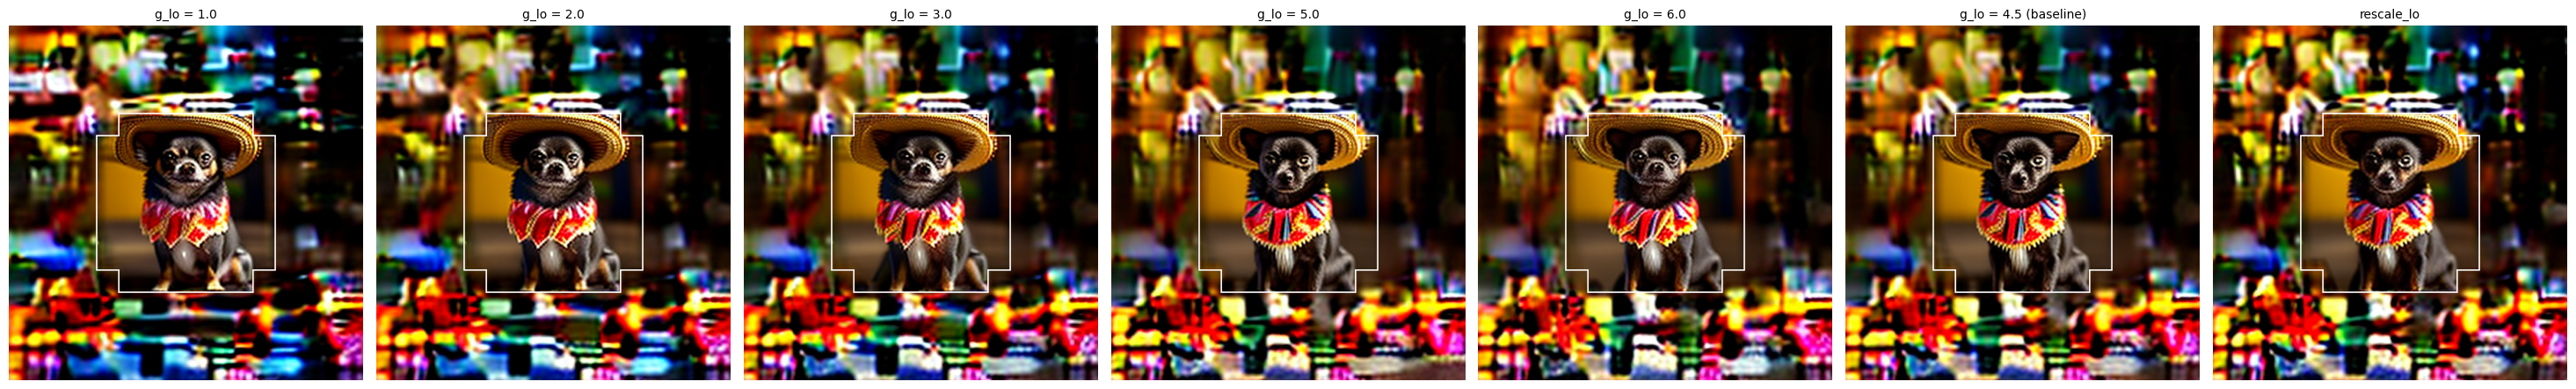

In [10]:
# Fovea fixed at 4.5, periphery swept. Same seed throughout, so differences are the guidance only.

RUNS = [("g_lo = 1.0", dict(guidance_scale_lo=1.0)),
        ("g_lo = 2.0", dict(guidance_scale_lo=2.0)),
        ("g_lo = 3.0", dict(guidance_scale_lo=3.0)),
        ("g_lo = 5.0", dict(guidance_scale_lo=5.0)),
        ("g_lo = 6.0", dict(guidance_scale_lo=6.0)),
        ("g_lo = 4.5 (baseline)", dict(guidance_scale_lo=None)),
        ("rescale_lo",            dict(rescale_lo=True))]

rows, imgs = [], []
for name, kw in RUNS:
    x = run_foveated_loop(layout, prompt_embeds, prompt_attention_mask,
                          seed=SEED, steps=STEPS, guidance_scale=GUIDANCE, **kw)
    hi = x[:, :layout["n_hi"]].float()
    lo = x[:, layout["n_hi"]:].float()
    rows.append((name, hi.std().item(), lo.std().item(),
                 lo.std().item() / hi.std().item(),
                 (lo.abs() > 4).float().mean().item() * 100))
    imgs.append((name, draw_fovea_border(decode_foveated(x, layout)[0], layout)))
    del x
    torch.cuda.empty_cache()

print(f"{'run':<24}{'fovea std':>11}{'periph std':>12}{'ratio':>9}{'|x|>4 %':>10}")
for name, s_hi, s_lo, r, pct in rows:
    print(f"{name:<24}{s_hi:>11.3f}{s_lo:>12.3f}{r:>9.3f}{pct:>10.2f}")
print("\nbaseline ratio measured in 3.3 Part B: 1.22   (saturation territory starts near std 1.8)")

fig, axs = plt.subplots(1, len(imgs), figsize=(4.2 * len(imgs), 4.6))
for ax, (name, im) in zip(np.atleast_1d(axs).ravel(), imgs):
    ax.imshow(im)
    ax.set_title(name, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

### 🟠4.5) different foveation patterns (same prompt and seed, like Fig. 9 in the paper)

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

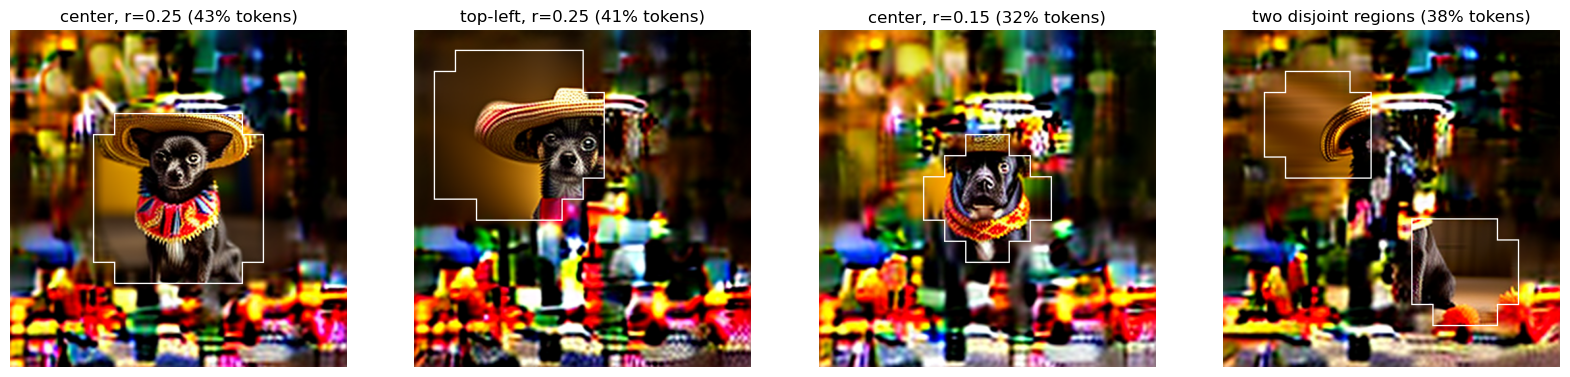

In [11]:
masks = {
    "center, r=0.25":       make_circular_mask((0.5, 0.5), 0.25),
    "top-left, r=0.25":     make_circular_mask((0.3, 0.3), 0.25),
    "center, r=0.15":       make_circular_mask((0.5, 0.5), 0.15),
    "two disjoint regions": make_circular_mask((0.3, 0.3), 0.15) | make_circular_mask((0.7, 0.7), 0.15),
}

fig, axes = plt.subplots(1, len(masks), figsize=(5 * len(masks), 5))
for ax, (name, M) in zip(axes, masks.items()):
    lay = build_layout(M)
    x = run_foveated_loop(lay, prompt_embeds, prompt_attention_mask, seed=SEED, steps=STEPS, guidance_scale=GUIDANCE)
    img_fov, _, _ = decode_foveated(x, lay)
    ax.imshow(draw_fovea_border(img_fov, lay))
    ax.set_title(f"{name} ({lay['token_ratio']:.0%} tokens)")
    ax.axis("off")
plt.show()

# 🔵5) solving the naive problems - LoRA

### Overcoming Naive Limitations via Parameter-Efficient Adaptation (LoRA)

Mixed-resolution denoising has three distinct problems. All figures below are measured by the diagnostic in section 3.3 rather than assumed.

1. **Mixed-resolution SNR mismatch (not variance collapse).** Because the 2x2 pooling windows do not overlap, `2*avg_pool2d(z, 2)` leaves white *noise* exactly iid N(0,1) — so the initial noise is statistically correct and there is no variance collapse. What the `*2` inflates is the *signal*: latents are spatially correlated (measured within-block correlation rho = 0.68), so pooling and rescaling multiplies the clean-signal std by **1.75x**. Peripheral tokens therefore carry an SNR that does not match the timestep they are labelled with. No single scalar can fix this, since the variance-preserving factor is 2.0 for pure noise but ~1.0 for clean signal.
2. **High-frequency boundary discontinuities (mosaic artifacts).** DiT attention is permutation-equivariant and does not itself assume a uniform grid; the uniform-sampling-rate assumption lives in the pretrained weights and the positional embedding. With peripheral tokens sitting at fractional positions and covering 4x the area, the model's prior on how quickly content changes between neighbouring tokens breaks at the interface. The block-snapped mask (a 32-pixel staircase) and the hard binary blend in `decode_foveated` then turn any mismatch into a visible seam.
3. **Off-manifold peripheral latents.** The VAE encoder is nonlinear, so `pool(E(x)) != E(Down(x))` and a pooled latent is not the latent of any image. Decoded directly, `2*pool(E(x))` drives **48.1%** of its output pixels outside [-1, 1] at **16.1 dB**, against **6.0%** and **22.2 dB** for the paper's `E(Down(x))`. Removing only the `*2` gives 16.1% / 18.9 dB — so roughly half the loss is amplitude, which decode-time calibration can recover, and half is the manifold error, which only a change of training target can. Note this is a property of our *training targets*: the naive baseline's own final latents are comparatively mild (periphery std 1.30 vs fovea 1.06, no values beyond +/-4), so the pooling convention introduces this saturation risk into the trained model rather than LoRA removing it from the naive one.

#### The Solution: Mixed-Resolution LoRA Fine-Tuning
Rather than retraining the entire 600M-parameter DiT backbone from scratch, we inject **Low-Rank Adaptation (LoRA)** into the Multi-Head Attention and MLP projections. By training LoRA on synthetically constructed mixed-resolution token sequences, the model learns to bridge cross-resolution feature distributions and predict dual-scale noise trajectories accurately.

#### Implementation Roadmap
To maintain strict memory safety on an 8GB VRAM constraint, we structure this pipeline into four modular stages:

In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_id = "PixArt-alpha/PixArt-XL-2-512x512"

# Clean peripheral training target (section 3.3 Part A compares them):
#   "downsample" -> z_lo = E(Down(x))      paper Eq. 9, a real latent
#   "pool"       -> z_lo = 2 * pool(E(x))  the original convention
# Each mode has its own cache and LoRA directory.
TARGET_MODE = "downsample"

# DiffusionDB subset size: 1000, 5000, 10000, ... (each 1k is a ~0.8 GB download).
# Training runs 15,000 steps, so 1k images = 15 passes, with a new random fovea every step.
N_IMAGES  = 1000
DB_CONFIG = f"2m_random_{N_IMAGES // 1000}k"

# The dataset size is part of the run name, so different sizes never share a cache or LoRA.
# 1k keeps the unsuffixed names of the existing artifacts.
SIZE_TAG = "" if N_IMAGES == 1000 else f"_{N_IMAGES // 1000}k"

if TARGET_MODE == "pool" and N_IMAGES == 1000:   # legacy names of existing artifacts
    RUN_TAG    = "pool"
    lora_dir   = "./pixart_foveated_lora_1hour_final"
    cache_file = "diffusiondb_512_cached_data.pt"
else:
    RUN_TAG    = f"{TARGET_MODE}{SIZE_TAG}"
    lora_dir   = f"./pixart_foveated_lora_{RUN_TAG}"
    cache_file = f"diffusiondb_512_cached_{RUN_TAG}.pt"

FORCE_RECACHE = False   # True: re-cache the data and retrain even if a LoRA exists

### 🟠5.1) Offline text and VAE latent caching to eliminate redundant forward passes.

To maximize training throughput and prevent GPU Out-of-Memory (OOM) crashes, we pre-encode the training set:
1. **Text Caching:** `N_IMAGES` prompt descriptions from DiffusionDB are tokenized and processed through T5 once. The resulting embeddings and attention masks are moved to system RAM, after which the 10GB T5 model is purged from GPU memory. Each embedding is stored trimmed to its real token count instead of the padded 120: the padded tail is 0.94 MB per sample that the cross-attention bias masks out of every forward pass anyway, so at 10k samples keeping it would cost ~7 GB of RAM for values the model never reads. `get_text` re-pads on demand.
2. **Latent Caching ($x_0$):** Target images are resized to the target spatial dimension and encoded via tiled `AutoencoderKL` into clean latent representations ($x_0$), scaled by the model's latent factor, and cached. This eliminates repetitive VAE forward passes during gradient descent.

In [13]:
import os
import gc
import torch
import torch.nn.functional as F
import torchvision.transforms as T
from tqdm.auto import tqdm
from diffusers import AutoencoderKL
from transformers import T5EncoderModel, T5Tokenizer

TEXT_MAX_LEN = 120      # PixArt's fixed prompt length. The cache stores less; get_text re-pads.

if os.path.exists(lora_dir) and not FORCE_RECACHE:
    print(f" Pre-trained LoRA found at '{lora_dir}'.")
    print(" No need to cache training data. You can skip directly to inference (Block 4)!")
    cached_text_embeds, cached_text_masks, cached_x0, cached_x0_lo = [], [], [], []

elif os.path.exists(cache_file) and not FORCE_RECACHE:
    print(f" Found cached dataset on disk ('{cache_file}'). Loading into RAM...")
    saved_data = torch.load(cache_file, map_location="cpu")
    cached_text_embeds = saved_data["text_embeds"]
    cached_text_masks = saved_data["text_masks"]
    cached_x0 = saved_data["x0"]
    cached_x0_lo = saved_data.get("x0_lo", [])
    print(f" Loaded {len(cached_x0)} samples in 2 seconds! Ready for training.")
    if TARGET_MODE == "downsample" and len(cached_x0_lo) != len(cached_x0):
        print(" This cache has no low-res latents. Set FORCE_RECACHE=True and rerun this cell.")
    if len(cached_x0) != N_IMAGES:
        print(f" Note: this cache holds {len(cached_x0)} samples but N_IMAGES is {N_IMAGES}.")

else:
    print("No cache found. Running full data caching pipeline...")

    from datasets import load_dataset   # only needed when re-caching

    # 1. load DiffusionDB. It is a script-based dataset: datasets >= 2.16 needs
    #    trust_remote_code, older versions reject the keyword.
    print(f"1. Loading {N_IMAGES:,} samples from DiffusionDB ({DB_CONFIG})...")
    try:
        dataset = load_dataset("poloclub/diffusiondb", DB_CONFIG, split="train",
                               trust_remote_code=True)
    except TypeError:
        dataset = load_dataset("poloclub/diffusiondb", DB_CONFIG, split="train")

    # 2. encode the prompts with T5
    print(f"2. Caching {N_IMAGES:,} Text Embeddings...")
    tokenizer = T5Tokenizer.from_pretrained(model_id, subfolder="tokenizer")
    text_encoder = T5EncoderModel.from_pretrained(
        model_id, subfolder="text_encoder", torch_dtype=torch.bfloat16
    ).to(device)

    cached_text_embeds = []
    cached_text_masks = []

    # column access reads the prompts without decoding the images
    with torch.no_grad():
        for prompt in tqdm(dataset["prompt"], desc="Encoding prompts"):
            txt_in = tokenizer(
                prompt, padding="max_length", max_length=TEXT_MAX_LEN, truncation=True,
                return_tensors="pt"
            ).to(device)
            emb = text_encoder(txt_in.input_ids, attention_mask=txt_in.attention_mask)[0]

            # keep only the real tokens to save RAM; get_text() re-pads
            n_tok = int(txt_in.attention_mask[0].sum())
            cached_text_embeds.append(emb[:, :n_tok].cpu())
            cached_text_masks.append(txt_in.attention_mask[:, :n_tok].cpu())

    del text_encoder, tokenizer
    torch.cuda.empty_cache()
    gc.collect()

    # 3. encode the images with the VAE
    print(f"3. Encoding {N_IMAGES:,} images directly via VAE...")
    vae = AutoencoderKL.from_pretrained(
        model_id, subfolder="vae", torch_dtype=torch.bfloat16
    ).to(device)

    img_transform = T.Compose([
        T.Resize((512, 512)),
        T.ToTensor(),
        T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
    ])

    cached_x0, cached_x0_lo = [], []
    SF = vae.config.scaling_factor

    with torch.no_grad():
        for item in tqdm(dataset, desc="VAE Encoding"):
            img = item["image"].convert("RGB")
            img_tensor = img_transform(img).unsqueeze(0).to(device=device, dtype=torch.bfloat16)

            # .mean, not .sample(): posterior noise would blur the target and decorrelate the
            # fine and coarse targets of the same image
            latent = vae.encode(img_tensor).latent_dist.mean * SF
            cached_x0.append(latent.cpu())

            if TARGET_MODE == "downsample":
                # paper Eq. 9: downsample the image, then encode, so the target is a real latent
                img_lo = F.interpolate(img_tensor.float(), scale_factor=0.5,
                                       mode="bicubic", antialias=True).clamp(-1, 1)
                latent_lo = vae.encode(img_lo.to(img_tensor.dtype)).latent_dist.mean * SF
                cached_x0_lo.append(latent_lo.cpu())

    del vae
    torch.cuda.empty_cache()
    gc.collect()

    # 4. save to disk for later runs
    print(f"Saving cached data to '{cache_file}'...")
    torch.save({
        "text_embeds": cached_text_embeds,      # trimmed to the real token count, see get_text()
        "text_masks": cached_text_masks,
        "x0": cached_x0,
        "x0_lo": cached_x0_lo,
        "target_mode": TARGET_MODE,
        "db_config": DB_CONFIG,
        "text_max_len": TEXT_MAX_LEN,
    }, cache_file)

    print(f"Data caching complete! {len(cached_x0)} latents & embeddings ready in RAM and saved to disk.")


def get_text(idx, dtype=torch.bfloat16):
    """
    Prompt `idx` re-padded to the (1, 120, 4096) embedding and (1, 120) mask PixArt expects.
    Zero padding is exact: masked positions get a -10000 attention bias.
    """
    emb, mask = cached_text_embeds[idx], cached_text_masks[idx]
    pad = TEXT_MAX_LEN - emb.shape[1]
    if pad > 0:
        emb = F.pad(emb, (0, 0, 0, pad))
        mask = F.pad(mask, (0, pad))
    return emb.to(device=device, dtype=dtype), mask.to(device)


if cached_text_embeds:
    avg_tok = sum(e.shape[1] for e in cached_text_embeds) / len(cached_text_embeds)
    gb = sum(e.numel() * e.element_size() for e in cached_text_embeds) / 1024 ** 3
    print(f"{len(cached_text_embeds)} prompts, {avg_tok:.0f} of {TEXT_MAX_LEN} tokens used on "
          f"average, {gb:.2f} GB of embeddings in RAM")
print(f"VRAM currently allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

Note: you may need to restart the kernel to use updated packages.
 Pre-trained LoRA found at './pixart_foveated_lora_downsample'.
 No need to cache training data. You can skip directly to inference (Block 4)!
VRAM currently allocated: 1.33 GB


### 🟠5.2) Spatial infrastructure definition (patchification, dynamic layout extraction) and LoRA injection ($r=32$).

This block sets up the spatial machinery required to handle irregular, non-grid token sequences:
1. **Patch Operators:** `patchify` flattens continuous 2D latents into discrete tokens ($P=2$), while `unpatchify` inverts the sequence back to spatial tensors.
2. **Dynamic Layout & Positional Routing:** `build_layout` constructs an asymmetric coordinate layout from a binary mask $M$, extracting ground-truth 2D sinusoidal positional embeddings for both full-resolution fovea and downsampled peripheral coordinates.
3. **LoRA Injection:** We apply LoRA ($r=32, \alpha=64$) targeting query, key, value, output projection, and feed-forward MLP layers (`to_q`, `to_k`, `to_v`, `to_out`, `net.0.proj`, `net.2`), optimizing cross-resolution interactions with minimal trainable parameter overhead.

In [14]:
import os
from peft import LoraConfig, get_peft_model, PeftModel
from diffusers import Transformer2DModel

print("Loading Transformer...")
transformer = Transformer2DModel.from_pretrained(
    model_id, subfolder="transformer", torch_dtype=torch.bfloat16
).to(device)

if os.path.exists(lora_dir) and not FORCE_RECACHE:
    print(f" Pre-trained LoRA found at '{lora_dir}'. Loading & merging weights directly...")
    transformer = PeftModel.from_pretrained(transformer, lora_dir)
    transformer = transformer.merge_and_unload()
    transformer.eval()
    base_model = transformer
else:
    print(" Setting up NEW LoRA adapters for training...")
    lora_config = LoraConfig(
        r=32,
        lora_alpha=64,
        target_modules=[
            "to_q", "to_k", "to_v", "to_out.0",   # Self & Cross Attention
            "net.0.proj", "net.2"                 # MLP / FeedForward
        ],
        lora_dropout=0.05,
        bias="none"
    )
    transformer = get_peft_model(transformer, lora_config)
    transformer.enable_gradient_checkpointing()
    transformer.print_trainable_parameters()
    base_model = transformer.base_model.model

# spatial constants, needed for both training and inference
P = base_model.config.patch_size       # 2
C = base_model.config.in_channels      # 4
D = base_model.inner_dim               # 1152
pe_layer = base_model.pos_embed
GRID = pe_layer.height                 # 32 for the 512 model
POS_SCALE = pe_layer.base_size / pe_layer.height / pe_layer.interpolation_scale

print(f"Model ready on {device}. VRAM allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

Note: you may need to restart the kernel to use updated packages.
Loading Transformer...


Some weights of the model checkpoint at PixArt-alpha/PixArt-XL-2-512x512 were not used when initializing PixArtTransformer2DModel: 
 ['caption_projection.y_embedding']


 Pre-trained LoRA found at './pixart_foveated_lora_downsample'. Loading & merging weights directly...
Model ready on cuda. VRAM allocated: 1.33 GB


### 🟠5.3) The mixed-resolution LoRA training loop: 15,000 steps over 1,000 images, a random fovea every step.

We train the LoRA adapters to adapt to asymmetric spatial inputs across arbitrary timesteps $t \in [0, 1000]$:
1. **Random fovea every step:** each step draws a new circular mask with a random centre ($c \in [0.25, 0.75]^2$) and radius ($r \in [0.18, 0.40]$). The loop walks shuffled permutations of the 1,000 images, so 15,000 steps is 15 passes and every image is seen 15 times, each time under a different fovea. (Section 6.1 trains the other variant: 10,000 images, one pass, each with its own fixed Gabor mask.)
2. **Peripheral target:** under `TARGET_MODE = "downsample"` the coarse branch runs its own forward process from $E(\mathrm{Down}(x))$ (paper Eq. 9), a real latent of a real 256×256 image. The legacy `"pool"` mode instead builds it as $2\times$ average pooling of the fine latent, which calibrates the noise but inflates the clean signal; section 3.3 Part A measures the gap.
3. **Dual-Scale Optimization:** The Transformer predicts noise on the hybrid token sequence $x_t^{\text{fov}}$, optimized via MSE loss against composite foveal/peripheral ground-truth noise targets (`target_noise_fov`).

In [15]:
import os
import math
import random
import time
from tqdm.auto import tqdm
import torch.nn.functional as F
import matplotlib.pyplot as plt
from diffusers import DPMSolverMultistepScheduler


if os.path.exists(lora_dir) and not FORCE_RECACHE:
    print(f" Pre-trained LoRA weights already exist at '{lora_dir}'.")
    print(" Skipping 1-hour training loop completely! Proceed to Block 4 (Inference).")

elif len(globals().get("cached_x0", [])) == 0:
    print(" Training data not found in RAM. Please set FORCE_RECACHE=True and run Block 1 first.")

elif TARGET_MODE == "downsample" and len(globals().get("cached_x0_lo", [])) != len(cached_x0):
    print(" TARGET_MODE='downsample' needs the low-res latents, which this cache does not have.")
    print(" Set FORCE_RECACHE=True and rerun the caching cell.")

else:
    print(" Starting 1-Hour LoRA Training Pipeline...")

    # 1. scheduler, only needed for alphas_cumprod
    if "scheduler" not in globals() or scheduler is None:
        scheduler = DPMSolverMultistepScheduler.from_pretrained(model_id, subfolder="scheduler")

    # 2. foveated forward pass with the LoRA active (as fov_transformer in 4.2)
    def fov_transformer_train(model, x, t, layout, prompt_embeds, prompt_attention_mask):
        B = x.shape[0]
        base = model.base_model.model if hasattr(model, "base_model") else model
        pe = base.pos_embed
        
        # per-token patch embedding
        W_in = pe.proj.weight.permute(0, 2, 3, 1).reshape(D, P * P * C).to(x.dtype)
        bias = pe.proj.bias.to(x.dtype) if pe.proj.bias is not None else None
        h = F.linear(x, W_in, bias) + layout["pos"].to(x.dtype)

        # timestep and text conditioning
        t_emb, t_raw = base.adaln_single(
            t.expand(B), {"resolution": None, "aspect_ratio": None},
            batch_size=B, hidden_dtype=h.dtype
        )
        enc = base.caption_projection(prompt_embeds).view(B, -1, D)
        enc_bias = ((1 - prompt_attention_mask.to(h.dtype)) * -10000.0).unsqueeze(1)

        # all 28 blocks (LoRA in attention and MLP)
        for block in base.transformer_blocks:
            h = block(
                h,
                attention_mask=None,
                encoder_hidden_states=enc,
                encoder_attention_mask=enc_bias,
                timestep=t_emb,
                cross_attention_kwargs=None,
                class_labels=None
            )

        # Output projection
        shift, scale = (base.scale_shift_table[None] + t_raw[:, None]).chunk(2, dim=1)
        h = base.norm_out(h) * (1 + scale) + shift
        out = base.proj_out(h)
        out = out.reshape(B, -1, P * P, base.out_channels)[..., :C]
        return out.reshape(B, -1, P * P * C)

    # 3. optimizer over the LoRA parameters only
    trainable = [p for p in transformer.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(trainable, lr=1e-4, weight_decay=1e-2)
    print(f"optimising {sum(p.numel() for p in trainable) / 1e6:.1f}M LoRA parameters")

    # on the CPU, so indexing with a python int avoids a GPU sync every step
    alphas_cumprod = scheduler.alphas_cumprod.float().cpu()

    # latents are small enough to stay on the GPU; text embeddings stay in RAM (get_text)
    x0_all = torch.cat(cached_x0).to(device=device, dtype=torch.bfloat16)
    x0_lo_all = (torch.cat(cached_x0_lo).to(device=device, dtype=torch.bfloat16)
                 if TARGET_MODE == "downsample" else None)

    ACCUM = 4        # gradient accumulation: effective batch 4
    BASE_LR = 1e-4
    WARMUP = 200

    # 4. training loop, stops early after max_minutes
    def train_foveated_lora_1hour(num_steps=10000, max_minutes=55):
        transformer.train()
        progress_bar = tqdm(range(num_steps), desc=f"Training LoRA ({TARGET_MODE})")
        start_time = time.time()
        elapsed_min, ema, loss_hist, order = 0.0, None, [], []
        optimizer.zero_grad(set_to_none=True)

        for step in progress_bar:
            # time limit
            elapsed_min = (time.time() - start_time) / 60.0
            if elapsed_min > max_minutes:
                print(f"\nReached time limit of {max_minutes} minutes. Stopping training gracefully.")
                break

            # linear warmup, then cosine decay
            if step < WARMUP:
                lr = BASE_LR * (step + 1) / WARMUP
            else:
                prog = min(1.0, (step - WARMUP) / max(1, num_steps - WARMUP))
                lr = BASE_LR * 0.5 * (1 + math.cos(math.pi * prog))
            for pg in optimizer.param_groups:
                pg["lr"] = lr

            # a. next image, in shuffled passes so every image is seen equally often
            if not order:
                order = torch.randperm(x0_all.shape[0]).tolist()
            idx = order.pop()
            x0 = x0_all[idx:idx + 1]
            p_emb, p_mask = get_text(idx)

            # b. a new random fovea every step
            c_y, c_x = random.uniform(0.25, 0.75), random.uniform(0.25, 0.75)
            r = random.uniform(0.18, 0.40)
            layout = build_layout(make_circular_mask(center=(c_y, c_x), radius=r, grid=GRID))

            # c. timestep and noise
            ti = random.randrange(1000)
            a = float(alphas_cumprod[ti])
            t = torch.tensor([ti], device=device, dtype=torch.long)

            noise = torch.randn_like(x0)
            x_t = (a ** 0.5) * x0 + ((1 - a) ** 0.5) * noise

            # d. noisy peripheral latent and its noise target
            if TARGET_MODE == "downsample":
                # paper Eqs. 8-9: the coarse grid has its own clean latent and its own noise
                x0_lo = x0_lo_all[idx:idx + 1]
                noise_lo = torch.randn_like(x0_lo)
                x_t_lo = (a ** 0.5) * x0_lo + ((1 - a) ** 0.5) * noise_lo
            else:
                # legacy: pool the fine grid (inflates the clean signal 1.75x, see section 3.3)
                x_t_lo = (F.avg_pool2d(x_t.float(), 2) * 2).to(torch.bfloat16)
                noise_lo = (F.avg_pool2d(noise.float(), 2) * 2).to(torch.bfloat16)

            x_t_fov = torch.cat([
                patchify(x_t)[:, layout["hi_idx"]],
                patchify(x_t_lo)[:, layout["lo_idx"]]
            ], dim=1)

            target_noise_fov = torch.cat([
                patchify(noise)[:, layout["hi_idx"]],
                patchify(noise_lo)[:, layout["lo_idx"]]
            ], dim=1)

            # e. forward pass and loss
            pred_noise_fov = fov_transformer_train(transformer, x_t_fov, t, layout, p_emb, p_mask)
            loss = F.mse_loss(pred_noise_fov, target_noise_fov)
            (loss / ACCUM).backward()

            if (step + 1) % ACCUM == 0:
                torch.nn.utils.clip_grad_norm_(trainable, max_norm=1.0)
                optimizer.step()
                optimizer.zero_grad(set_to_none=True)

            # progress bar
            l = loss.item()
            ema = l if ema is None else 0.99 * ema + 0.01 * l
            loss_hist.append(ema)
            progress_bar.set_postfix({
                "Loss(ema)": f"{ema:.4f}",
                "lr": f"{lr:.1e}",
                "Time": f"{elapsed_min:.1f}m"
            })

            # checkpoint every 2,500 steps
            if (step + 1) % 2500 == 0:
                transformer.save_pretrained(f"./checkpoint_{RUN_TAG}_step_{step+1}")

        # final weights
        transformer.save_pretrained(lora_dir)
        print(f"\nTraining completed in {elapsed_min:.1f} minutes ({len(loss_hist)} steps). Saved to {lora_dir}")
        return loss_hist

    # 15,000 steps over 1,000 images = 15 passes
    loss_hist = train_foveated_lora_1hour(num_steps=15000, max_minutes=55)

    # a curve that has not flattened means the run was limited by the training budget
    plt.figure(figsize=(7, 3.5))
    plt.plot(loss_hist, lw=1)
    plt.xlabel("step")
    plt.ylabel("MSE (ema)")
    plt.title(f"LoRA training loss, TARGET_MODE = {TARGET_MODE}")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

 Pre-trained LoRA weights already exist at './pixart_foveated_lora_downsample'.
 Skipping 1-hour training loop completely! Proceed to Block 4 (Inference).


### 🟠5.4) Merged-weight fast foveated inference with calibrated dual-branch VAE reconstruction.

The final block evaluates the trained system under actual generation conditions:
1. **Zero-Overhead LoRA Merging:** We fuse the learned low-rank weights directly into the base transformer parameters (`merge_and_unload`), eliminating PEFT forward overhead and achieving peak inference iteration speed.
2. **Reduced Sequence Denoising:** Inference executes on only ~40–45% of the total token count, using DPM-Solver across 20 steps with Classifier-Free Guidance.
3. **Calibrated Dual Reconstruction (`decode_foveated_smooth`):** 
   * **Amplitude Matching:** We rescale the peripheral latents toward the foveal latent distribution and clamp to +/-3, which suppresses VAE decoder color blowout. This step is a *necessity created by the `2*pool` training convention* (see the 1.75x signal inflation in the section 5 intro), not an improvement over the paper — with `E(Down(x))` targets it is not needed. `std_ratio` is therefore computed **from the token tensors directly**, before they are scattered into the zero-filled grids. Taking `std()` of the scattered grids diluted both numbers by their zero fractions (about 0.48 and 0.88 at radius 0.25), so the factor tracked the *fovea area* rather than the amplitude mismatch and silently changed strength whenever the radius changed. Computing it from the tokens also makes the step self-disabling: it lands near 0.59 under `2*pool` and near 1.0 under `TARGET_MODE = "downsample"`, so a correctly-scaled periphery is left alone.
   * **Seam-matched cross-fill:** The foveal region of the coarse grid is filled from `avg_pool2d(z_hi, 2)` so the decoder never sees zeros beside the boundary. That fill is now rescaled to the amplitude of the calibrated periphery surrounding it; previously it was spliced in at its own natural scale *after* calibration had already moved the periphery, leaving an amplitude step right at the seam for the decoder to ring on.
   * **Artifact-Free Blending:** Peripheral latents are smoothly upsampled via bilinear interpolation and composited using a Gaussian-blurred transition mask, which removes the mosaic boundary produced by the hard binary blend in `decode_foveated`.

In [38]:
import os
import gc
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw
from tqdm.auto import tqdm
from diffusers import AutoencoderKL, Transformer2DModel, DPMSolverMultistepScheduler
from transformers import T5EncoderModel, T5Tokenizer
from peft import PeftModel

# 1. free the training leftovers (x0_all / x0_lo_all are on the GPU)
for var in ["optimizer", "trainable", "cached_x0", "cached_x0_lo", "x0_all", "x0_lo_all",
            "cached_text_embeds", "cached_text_masks"]:
    if var in globals():
        del globals()[var]
gc.collect()
torch.cuda.empty_cache()

# 2. spatial helpers, redefined so this cell stands alone
def to_pil(t):
    img = (t.detach().cpu().float().clamp(-1, 1) + 1) / 2
    return Image.fromarray((img.squeeze(0).permute(1, 2, 0).numpy() * 255).astype(np.uint8))

def patchify(x):
    B, c, h, w = x.shape
    return x.reshape(B, c, h // P, P, w // P, P).permute(0, 2, 4, 3, 5, 1).reshape(B, -1, P * P * c)

def unpatchify(x, gh, gw):
    B, _, _ = x.shape
    return x.reshape(B, gh, gw, P, P, C).permute(0, 5, 1, 3, 2, 4).reshape(B, C, gh * P, gw * P)

def draw_fovea_border(pil_img, layout, color="red", width=3):
    img_draw = pil_img.copy()
    draw = ImageDraw.Draw(img_draw)
    M = layout["M"].cpu().numpy()
    gh, gw = M.shape
    w_px, h_px = pil_img.size
    
    # centre and radius from the mask extent
    y_indices, x_indices = np.where(M)
    if len(x_indices) > 0 and len(y_indices) > 0:
        cx = (x_indices.min() + x_indices.max()) / 2.0 / gw * w_px
        cy = (y_indices.min() + y_indices.max()) / 2.0 / gh * h_px
        r = ((x_indices.max() - x_indices.min()) / 2.0 / gw) * w_px
        draw.ellipse([cx - r, cy - r, cx + r, cy + r], outline=color, width=width)
    return img_draw

# 3. load the transformer and merge the LoRA
print("Ensuring Transformer & LoRA are loaded...")
if "transformer" not in globals() or transformer is None or hasattr(transformer, "peft_config"):
    transformer = Transformer2DModel.from_pretrained(
        model_id, subfolder="transformer", torch_dtype=torch.bfloat16
    ).to(device)
    
    if os.path.exists(lora_dir):
        print(f" Loading LoRA weights from '{lora_dir}'...")
        transformer = PeftModel.from_pretrained(transformer, lora_dir)
        transformer = transformer.merge_and_unload()
    else:
        print(" Warning: No LoRA weights found. Running zero-shot base model.")

transformer.eval()
base_model = transformer
P = base_model.config.patch_size       # 2
C = base_model.config.in_channels      # 4
D = base_model.inner_dim               # 1152
pe_layer = base_model.pos_embed
GRID = pe_layer.height                 # 32
model_dtype = pe_layer.proj.weight.dtype

# 4. VAE and scheduler
if "vae" not in globals() or vae is None:
    vae = AutoencoderKL.from_pretrained(
        model_id, subfolder="vae", torch_dtype=torch.float16
    ).to(device)

if "scheduler" not in globals() or scheduler is None:
    scheduler = DPMSolverMultistepScheduler.from_pretrained(model_id, subfolder="scheduler")

# 5. encode the test prompt
test_prompt = "a dog with a mexican hat"

print(f"Encoding inference prompt: '{test_prompt}'...")
tokenizer = T5Tokenizer.from_pretrained(model_id, subfolder="tokenizer")
text_encoder = T5EncoderModel.from_pretrained(
    model_id, subfolder="text_encoder", torch_dtype=torch.bfloat16
).to(device)

with torch.no_grad():
    txt_in = tokenizer(
        ["" , test_prompt], padding="max_length", max_length=120, truncation=True, return_tensors="pt"
    ).to(device)
    prompt_embeds = text_encoder(txt_in.input_ids, attention_mask=txt_in.attention_mask)[0].to(model_dtype)
    prompt_attention_mask = txt_in.attention_mask.to(device)

del text_encoder, tokenizer
torch.cuda.empty_cache()

# 6. centred fovea
M = make_circular_mask(center=(0.5, 0.5), radius=0.28, grid=GRID)
layout = build_layout(M)

# 7. foveated forward pass (LoRA already merged)
@torch.no_grad()
def fov_transformer_inference(x, t, layout, p_emb, p_mask):
    B = x.shape[0]
    base = transformer
    pe = base.pos_embed

    W_in = pe.proj.weight.permute(0, 2, 3, 1).reshape(D, P * P * C).to(model_dtype)
    bias = pe.proj.bias.to(model_dtype) if pe.proj.bias is not None else None
    h = F.linear(x, W_in, bias) + layout["pos"].to(model_dtype)

    t_emb, t_raw = base.adaln_single(
        t.expand(B), {"resolution": None, "aspect_ratio": None},
        batch_size=B, hidden_dtype=model_dtype
    )
    enc = base.caption_projection(p_emb).view(B, -1, D)
    enc_bias = ((1 - p_mask.to(model_dtype)) * -10000.0).unsqueeze(1)

    for block in base.transformer_blocks:
        h = block(
            h,
            attention_mask=None,
            encoder_hidden_states=enc,
            encoder_attention_mask=enc_bias,
            timestep=t_emb,
            cross_attention_kwargs=None,
            class_labels=None
        )

    shift, scale = (base.scale_shift_table[None] + t_raw[:, None]).chunk(2, dim=1)
    h = base.norm_out(h) * (1 + scale) + shift
    out = base.proj_out(h)
    out = out.reshape(B, -1, P * P, base.out_channels)[..., :C]
    return out.reshape(B, -1, P * P * C)

# 8. initial foveated noise
def foveated_noise(layout, seed=42):
    g = torch.Generator(device=device).manual_seed(seed)
    lat_hi = torch.randn(1, C, layout["h"] * P, layout["w"] * P, generator=g, device=device, dtype=model_dtype)
    lat_lo = (F.avg_pool2d(lat_hi.float(), 2) * 2).to(model_dtype)
    return torch.cat([patchify(lat_hi)[:, layout["hi_idx"]], patchify(lat_lo)[:, layout["lo_idx"]]], dim=1)

# 9. denoising loop
@torch.no_grad()
def generate_foveated_fast(seed=42, steps=20, guidance_scale=3.5):
    scheduler.set_timesteps(steps)
    x = foveated_noise(layout, seed) * scheduler.init_noise_sigma

    print(f"Generating image ({layout['token_ratio']*100:.0f}% tokens)...")
    for t in tqdm(scheduler.timesteps):
        t = t.to(device)
        x_in = scheduler.scale_model_input(torch.cat([x] * 2), t).to(model_dtype)

        eps_pred = fov_transformer_inference(x_in, t, layout, prompt_embeds, prompt_attention_mask)
        eps_uncond, eps_text = eps_pred.chunk(2)
        eps = eps_uncond + guidance_scale * (eps_text - eps_uncond)

        x = scheduler.step(eps, t, x).prev_sample
    return x

# 10. calibrated decoding: amplitude matching, bilinear fill, soft seam
@torch.no_grad()
def decode_foveated_smooth(x, layout):
    h, w, n_hi = layout["h"], layout["w"], layout["n_hi"]
    hi = torch.zeros(1, h * w, P * P * C, device=device, dtype=x.dtype)
    lo = torch.zeros(1, (h // 2) * (w // 2), P * P * C, device=device, dtype=x.dtype)
    hi[:, layout["hi_idx"]] = x[:, :n_hi]
    lo[:, layout["lo_idx"]] = x[:, n_hi:]
    z_hi, z_lo = unpatchify(hi, h, w), unpatchify(lo, h // 2, w // 2)

    # amplitude calibration, computed from the tokens (zero-filled grids would dilute the stds).
    # ~0.59 under '2*pool' training, ~1.0 under E(Down(x)), where it is effectively a no-op.
    tok_hi, tok_lo = x[:, :n_hi].float(), x[:, n_hi:].float()
    std_ratio = (tok_hi.std() / (tok_lo.std() + 1e-6)).item()
    z_lo = ((z_lo.float() - tok_lo.mean()) * std_ratio + tok_hi.mean()).to(z_hi.dtype)
    z_lo = z_lo.clamp(-3.0, 3.0)
    z_hi = z_hi.clamp(-3.0, 3.0)

    m_hi = layout["M"].repeat_interleave(P, 0).repeat_interleave(P, 1).to(device)
    m_lo = layout["Mb"].repeat_interleave(P, 0).repeat_interleave(P, 1).to(device)

    # fill the fovea hole at the calibrated periphery's amplitude, so the seam has no step
    fill = F.avg_pool2d(z_hi.float(), 2)
    src, tgt = fill[:, :, m_lo], z_lo.float()[:, :, ~m_lo]
    if src.numel() and tgt.numel():
        fill = (fill - src.mean()) * (tgt.std() / (src.std() + 1e-6)) + tgt.mean()
    z_lo = torch.where(m_lo, fill.to(z_lo.dtype), z_lo)

    # smooth bilinear upsampling of the periphery
    z_hi_smooth = F.interpolate(z_lo.float(), scale_factor=2, mode="bilinear", align_corners=False).to(z_hi.dtype)
    z_hi = torch.where(m_hi, z_hi, z_hi_smooth)

    img_hi = vae.decode((z_hi / vae.config.scaling_factor).to(vae.dtype)).sample
    img_lo = vae.decode((z_lo / vae.config.scaling_factor).to(vae.dtype)).sample
    img_lo_up = F.interpolate(img_lo.float(), scale_factor=2, mode="bicubic")

    # soft blend across the fovea border
    m_px = layout["M"].float().repeat_interleave(P * 8, 0).repeat_interleave(P * 8, 1).unsqueeze(0).to(device)
    m_px_smooth = TF.gaussian_blur(m_px, kernel_size=[11, 11], sigma=[3.0, 3.0]).squeeze(0)

    img = m_px_smooth * img_hi.float() + (1.0 - m_px_smooth) * img_lo_up
    return to_pil(img), to_pil(img_hi), to_pil(img_lo)

Ensuring Transformer & LoRA are loaded...


Some weights of the model checkpoint at PixArt-alpha/PixArt-XL-2-512x512 were not used when initializing PixArtTransformer2DModel: 
 ['caption_projection.y_embedding']


 Loading LoRA weights from './pixart_foveated_lora_downsample'...
Encoding inference prompt: 'a dog with a mexican hat'...


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Generating image (47% tokens)...


  0%|          | 0/20 [00:00<?, ?it/s]

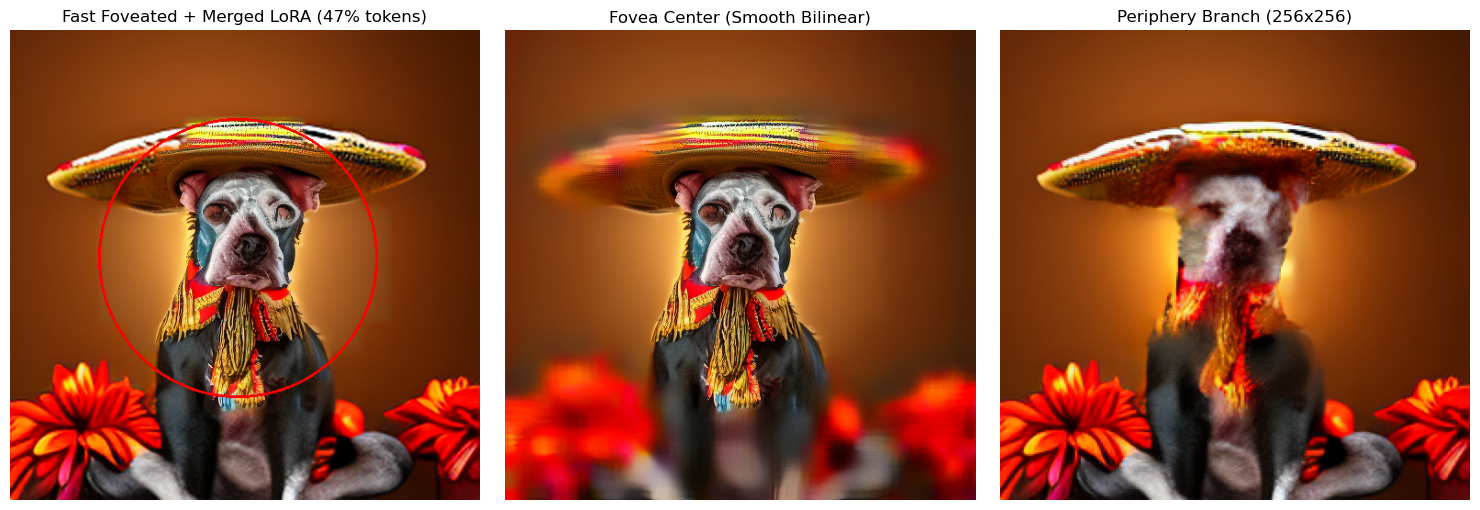

In [40]:
latents_out = generate_foveated_fast(seed=42, steps=20, guidance_scale=2)
img_blend, img_hi, img_lo = decode_foveated_smooth(latents_out, layout)
img_with_border = draw_fovea_border(img_blend, layout)

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(img_with_border)
axs[0].set_title(f"Fast Foveated + Merged LoRA ({layout['token_ratio']*100:.0f}% tokens)")
axs[0].axis("off")

axs[1].imshow(img_hi)
axs[1].set_title("Fovea Center (Smooth Bilinear)")
axs[1].axis("off")

axs[2].imshow(img_lo)
axs[2].set_title("Periphery Branch (256x256)")
axs[2].axis("off")

plt.tight_layout()
plt.show()

In [23]:
# Diagnostic: where does the trained model's periphery actually land, and is the
# amplitude calibration in decode_foveated_smooth doing what it intends?
# Run after the cell above (needs `latents_out` and `layout`).

import numpy as np
import torch.nn.functional as F

if "latents_out" not in globals():
    print("Run the generate_foveated_fast cell above first.")
else:
    SF = vae.config.scaling_factor
    h, w, n_hi = layout["h"], layout["w"], layout["n_hi"]
    x = latents_out
    tok_hi, tok_lo = x[:, :n_hi].float(), x[:, n_hi:].float()

    # --- 1. token-level statistics, same format as the naive test in section 3.3 ---
    print(f"trained (LoRA) foveated loop, token ratio {layout['token_ratio']:.0%}")
    print(f"{'final latents':<14}{'std':>7}{'mean':>8}{'absmax':>9}{'|x|>4':>9}")
    for name, t in (("foveal", tok_hi), ("peripheral", tok_lo)):
        frac = 100 * (t.abs() > 4).float().mean().item()
        print(f"{name:<14}{t.std().item():>7.3f}{t.mean().item():>8.3f}"
              f"{t.abs().max().item():>9.2f}{frac:>8.1f}%")

    s_hi, s_lo = tok_hi.std().item(), tok_lo.std().item()
    print(f"periphery/fovea std ratio: {s_lo / s_hi:.2f}   "
          "(~1.75 would mean the '2*pool' training convention was learned as-is)")

    # --- 2. calibration factor: from zero-filled grids (old method) vs from the tokens (current) ---
    hi_g = torch.zeros(1, h * w, P * P * C, device=x.device, dtype=x.dtype)
    lo_g = torch.zeros(1, (h // 2) * (w // 2), P * P * C, device=x.device, dtype=x.dtype)
    hi_g[:, layout["hi_idx"]] = x[:, :n_hi]
    lo_g[:, layout["lo_idx"]] = x[:, n_hi:]
    z_hi = unpatchify(hi_g, h, w).float()
    z_lo = unpatchify(lo_g, h // 2, w // 2).float()

    impl_ratio = (z_hi.std() / (z_lo.std() + 1e-6)).item()   # old: diluted by the zero fractions
    true_ratio = s_hi / s_lo                                 # current decode_foveated_smooth
    print(f"\nstd_ratio as implemented (zero-padded grids): {impl_ratio:.3f}")
    print(f"std_ratio from the tokens themselves        : {true_ratio:.3f}")
    print(f"dilution factor                             : {impl_ratio / true_ratio:.3f}"
          "   (should be 1.000; it depends on fovea area, not amplitude)")

    # --- 3. what each calibration choice does to the decoder ---
    m_lo = layout["Mb"].repeat_interleave(P, 0).repeat_interleave(P, 1).to(x.device)
    fill = F.avg_pool2d(z_hi, 2)

    def build_lo(scale):
        z = z_lo if scale is None else ((z_lo - z_lo.mean()) * scale + z_hi.mean()).clamp(-3.0, 3.0)
        return torch.where(m_lo, fill, z)

    print(f"\n{'peripheral branch':<28}{'latent std':>12}{'clipped px':>13}")
    for name, scale in (("uncalibrated", None),
                        ("calibrated (as implemented)", impl_ratio),
                        ("calibrated (token-level)", true_ratio)):
        z = build_lo(scale)
        img = vae.decode(z.to(vae.dtype) / SF).sample.float()
        clipped = 100 * ((img < -1) | (img > 1)).float().mean().item()
        print(f"{name:<28}{z[:, :, ~m_lo].std().item():>12.3f}{clipped:>12.1f}%")
    print(f"{'target (foveal tokens)':<28}{s_hi:>12.3f}")


trained (LoRA) foveated loop, token ratio 47%
final latents     std    mean   absmax    |x|>4
foveal          0.871   0.297     9.25     0.2%
peripheral      0.613   0.418     4.28     0.1%
periphery/fovea std ratio: 0.70   (~1.75 would mean the '2*pool' training convention was learned as-is)

std_ratio as implemented (zero-padded grids): 0.901
std_ratio from the tokens themselves        : 1.422
dilution factor                             : 0.633   (should be 1.000; it depends on fovea area, not amplitude)

peripheral branch             latent std   clipped px
uncalibrated                       0.613         0.0%
calibrated (as implemented)        0.548         0.0%
calibrated (token-level)           0.852         1.7%
target (foveal tokens)             0.871


# 6) Gabor filters
Creating the Gabor filters mask based on image

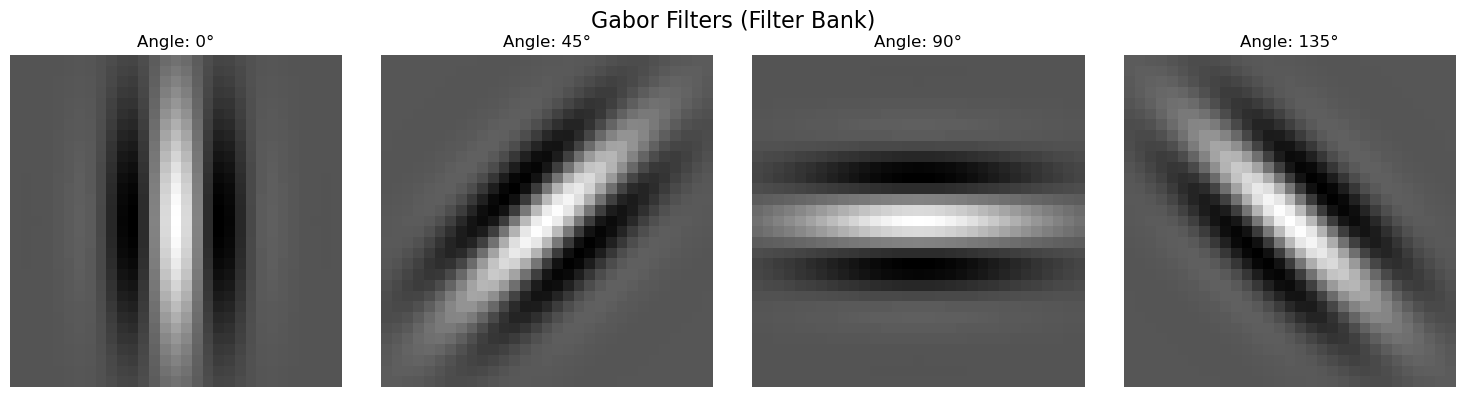

In [56]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def build_gabor_filters():
    """
    מייצר בנק של מסנני Gabor בזוויות שונות.
    ניתן לשחק עם הפרמטרים (ksize, sigma, lambd) כדי לתפוס טקסטורות עבות או עדינות יותר.
    """
    filters = []
    ksize = 31      # גודל המסנן (חייב להיות אי-זוגי)
    sigma = 4.0     # סטיית התקן (רוחב המעטפת הגאוסיאנית)
    lambd = 10.0    # אורך הגל של הפונקציה הסינוסואידלית
    gamma = 0.5     # יחס גובה-רוחב (אליפטיות)
    psi = 0         # היסט פאזה
    
    # נייצר מסננים ב-4 זוויות שונות: 0, 45, 90, 135 מעלות
    for theta in [0, np.pi/4, np.pi/2, np.pi*3/4]:
        kern = cv2.getGaborKernel((ksize, ksize), sigma, theta, lambd, gamma, psi, ktype=cv2.CV_32F)
        kern /= 1.5 * kern.sum()
        filters.append(kern)
    return filters

def generate_gabor_mask(image, threshold=0.4, blur_size=51):
    """
       takes an image, ang generates a gabor filter mask 
    """
    img_gray = np.array(image.convert("L"))
    
    filters = build_gabor_filters()
    
    gabor_response = np.zeros_like(img_gray, dtype=np.float32)
    for kern in filters:
        fimg = cv2.filter2D(img_gray, cv2.CV_32F, kern)
        gabor_response = np.maximum(gabor_response, np.abs(fimg))
    
    # 4. נרמול התגובה לטווח שבין 0 ל-1
    gabor_response = (gabor_response - gabor_response.min()) / (gabor_response.max() - gabor_response.min() + 1e-5)
    
    # 5. החלקה משמעותית (Gaussian Blur) כדי להפוך את הקצוות המפורקים למסכה רציפה אחידה
    smoothed_mask = cv2.GaussianBlur(gabor_response, (blur_size, blur_size), 0)
    smoothed_mask = (smoothed_mask - smoothed_mask.min()) / (smoothed_mask.max() - smoothed_mask.min() + 1e-5)
    
    # 6. יצירת מסכה בינארית (או רכה) לפי סף
    binary_mask = (smoothed_mask > threshold).astype(np.float32)
    
    return smoothed_mask, binary_mask

# יצירת בנק המסננים מהפונקציה שכבר הגדרת
filters = build_gabor_filters()
angles = ['0°', '45°', '90°', '135°']

# ציור המסננים
fig, axs = plt.subplots(1, 4, figsize=(15, 4))
fig.suptitle("Gabor Filters (Filter Bank)", fontsize=16)

for i, kern in enumerate(filters):
    axs[i].imshow(kern, cmap='gray')
    axs[i].set_title(f"Angle: {angles[i]}")
    axs[i].axis('off')

plt.tight_layout()
plt.show()

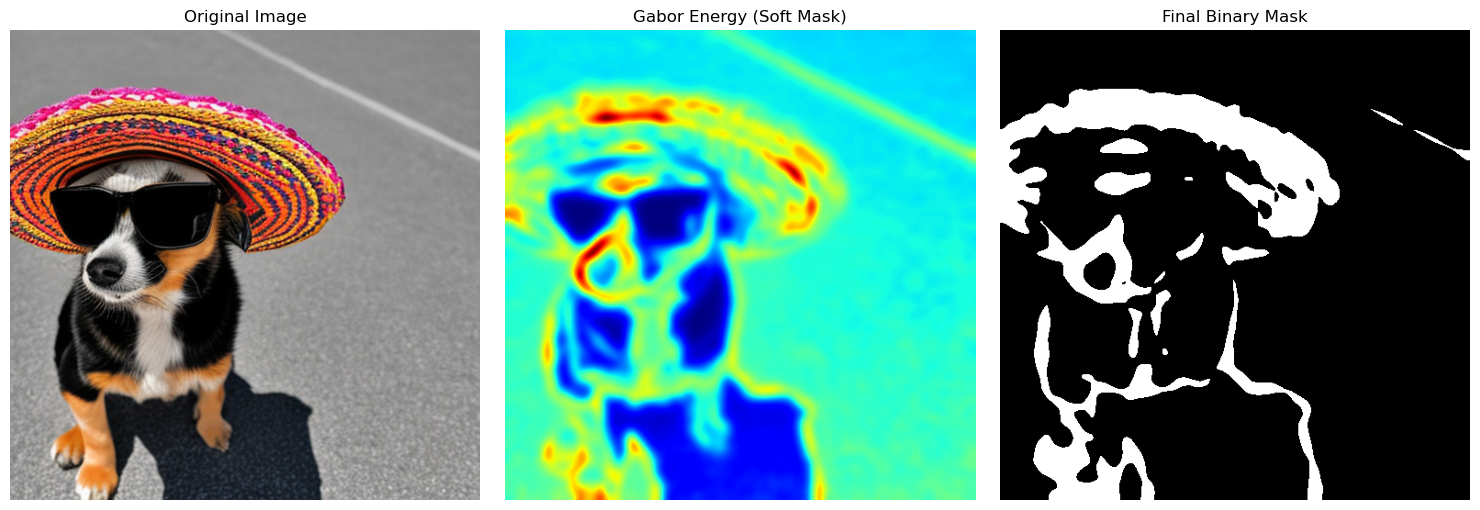

In [57]:
image_path = r"./final.png" 


img = Image.open(image_path).convert("RGB").resize((512, 512))
soft_mask, bin_mask = generate_gabor_mask(img, threshold=0.5, blur_size=31)

# הצגה
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(img)
axs[0].set_title("Original Image")
axs[0].axis('off')

axs[1].imshow(soft_mask, cmap='jet')
axs[1].set_title("Gabor Energy (Soft Mask)")
axs[1].axis('off')

axs[2].imshow(bin_mask, cmap='gray')
axs[2].set_title("Final Binary Mask")
axs[2].axis('off')

plt.tight_layout()
plt.show()

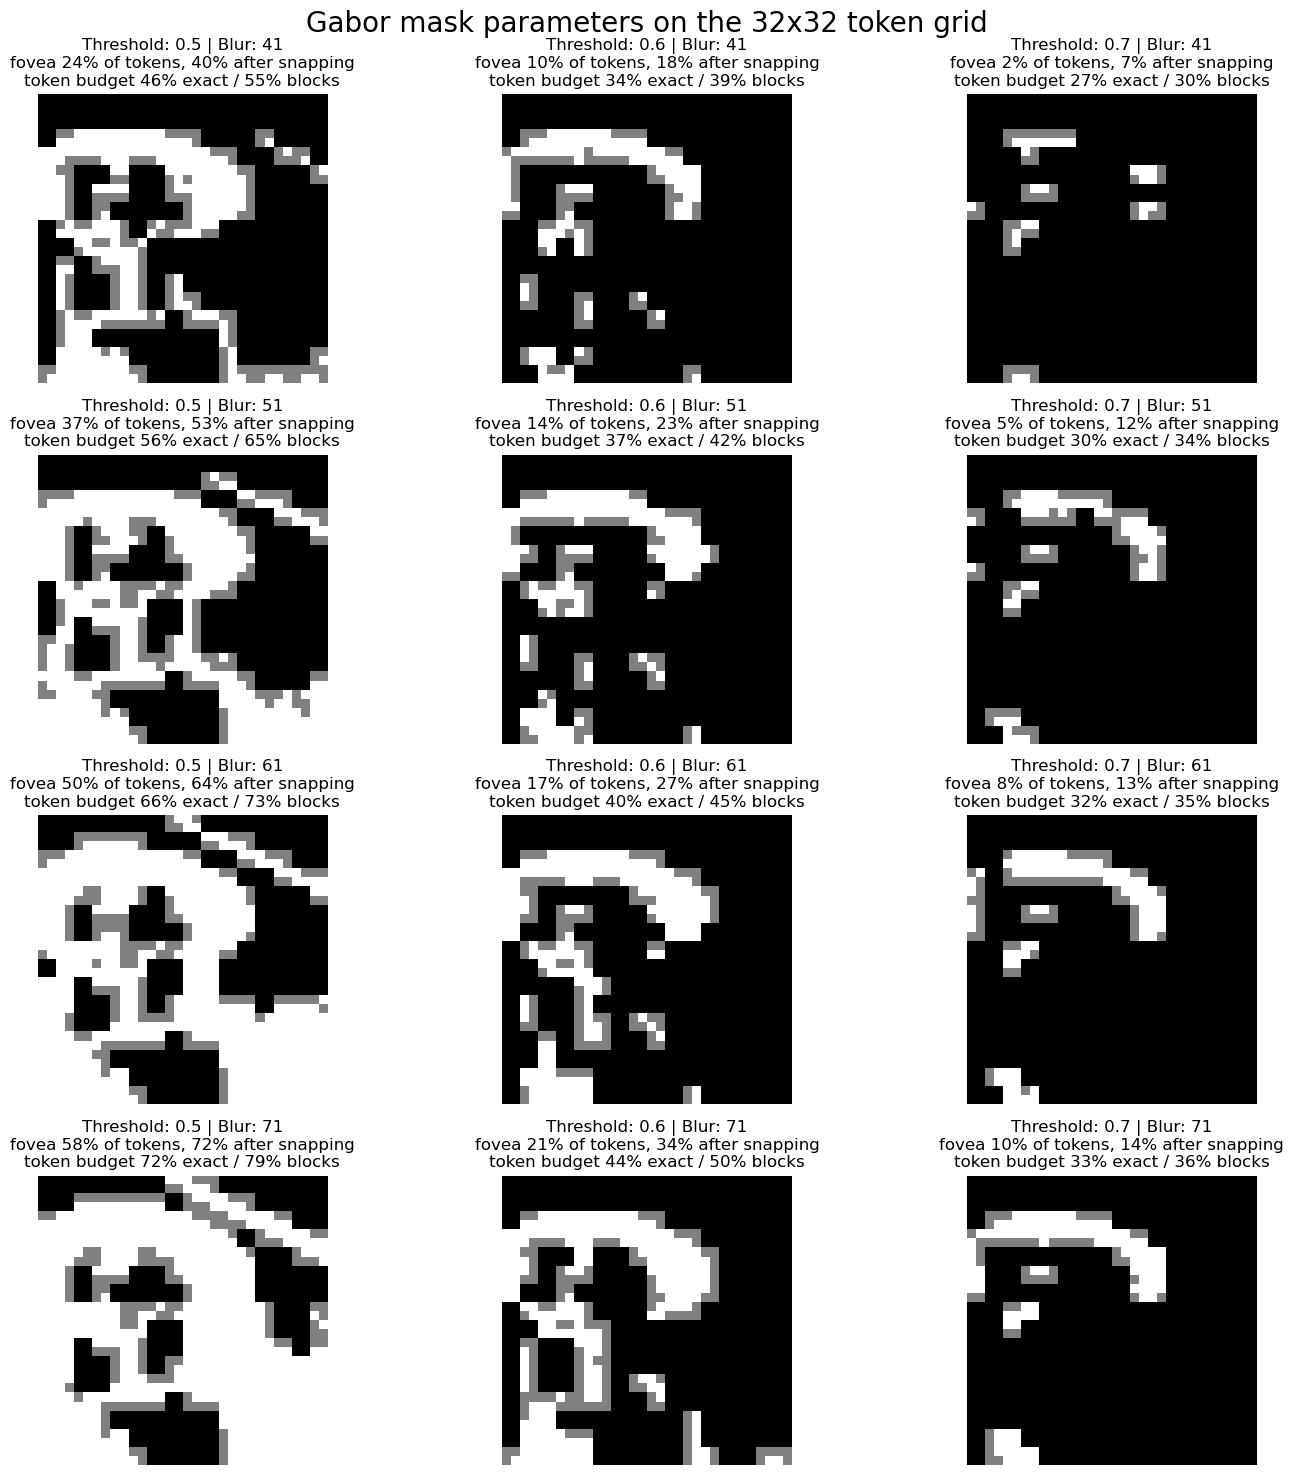

In [60]:
# The same threshold/blur sweep, but shown the way the model actually consumes it: the 512x512
# binary mask reduced to the 32x32 token grid, the identical reduction gabor_token_mask does in 6.1a.
# White = fovea at token resolution, grey = tokens that 2x2 block snapping adds on top of it.
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

thresholds = [0.5,0.6, 0.7]
blur_sizes = [41, 51, 61, 71]
TOKEN_GRID = 32            # 512 / (8 VAE * 2 patch): one token covers 16x16 pixels

def to_token_grid(bin_mask, grid=TOKEN_GRID):
    """Majority vote over each token's 16x16 pixels."""
    m = F.interpolate(torch.from_numpy(bin_mask)[None, None], size=(grid, grid), mode="area")
    return m[0, 0] > 0.5

def routing(M):
    """Block-snapped fovea, and what each routing mode costs out of grid*grid fine tokens."""
    blk = M.reshape(M.shape[0] // 2, 2, M.shape[1] // 2, 2)
    snapped = blk.any(dim=3).any(dim=1)          # a block is fovea if any of its 4 tokens is
    full = blk.all(dim=3).all(dim=1)             # only these give up their coarse token
    n_exact = int(M.sum()) + int((~full).sum())  # fine tokens + one coarse per not-fully-fovea block
    n_snap = 4 * int(snapped.sum()) + int((~snapped).sum())
    M_snap = snapped.repeat_interleave(2, 0).repeat_interleave(2, 1)
    return M_snap, n_exact / M.numel(), n_snap / M.numel()

fig, axs = plt.subplots(len(blur_sizes), len(thresholds), figsize=(15, 15))
fig.suptitle(f"Gabor mask parameters on the {TOKEN_GRID}x{TOKEN_GRID} token grid", fontsize=20, y=0.98)

for i, b_size in enumerate(blur_sizes):
    for j, thresh in enumerate(thresholds):
        _, bin_mask = generate_gabor_mask(img, threshold=thresh, blur_size=b_size)
        M = to_token_grid(bin_mask)
        M_snap, r_exact, r_snap = routing(M)

        vis = M.float()
        vis[M_snap & ~M] = 0.5
        axs[i, j].imshow(vis, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axs[i, j].set_title(f"Threshold: {thresh} | Blur: {b_size}\n"
                            f"fovea {M.float().mean():.0%} of tokens, {M_snap.float().mean():.0%} after snapping\n"
                            f"token budget {r_exact:.0%} exact / {r_snap:.0%} blocks", fontsize=12)
        axs[i, j].axis("off")

plt.tight_layout()
plt.show()


In [22]:
from datasets import load_dataset
import torch
from tqdm import tqdm
from transformers import T5Tokenizer, T5EncoderModel
import torchvision.transforms.functional as TF

# טעינת נתונים ומודל שפה
dataset = load_dataset("poloclub/diffusiondb", "2m_random_10k", split="train")
tokenizer = T5Tokenizer.from_pretrained(model_id, subfolder="tokenizer")
text_encoder = T5EncoderModel.from_pretrained(
    model_id, subfolder="text_encoder", torch_dtype=torch.bfloat16
).to(device)

@torch.no_grad()
def encode_prompt_only(prompt):
    txt_in = tokenizer(
        [prompt], padding="max_length", max_length=120, truncation=True, return_tensors="pt"
    ).to(device)
    prompt_embeds = text_encoder(txt_in.input_ids, attention_mask=txt_in.attention_mask)[0]
    return prompt_embeds.to(torch.float32) # נשמור ב-float32 לאימון יציב של ה-CVAE

training_data = []
NUM_SAMPLES = 5000 

print(f"Generating Dataset directly from images ({NUM_SAMPLES} samples)...")
for i in tqdm(range(NUM_SAMPLES)):
    item = dataset[i]
    prompt = item["prompt"]
    real_image = item["image"] # תמונת PIL אמיתית שכבר קיימת במאגר!
    
    # 1. קידוד טקסט
    prompt_embeds = encode_prompt_only(prompt)
    
    # 2. חילוץ מסכה מהתמונה הקיימת
    _, bin_mask = generate_gabor_mask(real_image, threshold=0.5, blur_size=61)
    
    # 3. המרה לטנזור 32x32
    mask_tensor = torch.tensor(bin_mask, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
    mask_32 = torch.nn.functional.interpolate(mask_tensor, size=(32, 32), mode="nearest").squeeze()
    
    # שמירה (טקסט ומסכה בלבד!)
    training_data.append({
        "text": prompt_embeds.cpu().squeeze(0), # [120, 4096]
        "mask": mask_32.cpu()                   # [32, 32]
    })

torch.save(training_data, "foveation_cvae_dataset.pt")
print("CVAE Dataset saved!")

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Generating Dataset directly from images (5000 samples)...


  4%|████▊                                                                                                               | 209/5000 [00:17<06:51, 11.64it/s]


KeyboardInterrupt: 

In [26]:
import torch.nn as nn
import torch.nn.functional as F

class MaskCVAE(nn.Module):
    def __init__(self, text_dim=4096, latent_dim=128):
        super().__init__()
        self.latent_dim = latent_dim
        
        # כיווץ הטקסט מוקטור רציף (120 מילים) לוקטור יחיד שמייצג את המשמעות
        self.text_pool = nn.AdaptiveAvgPool1d(1)
        
        # ================= ENCODER =================
        # מקבל מסכה (1x32x32) -> מכווץ לוקטור
        self.enc_conv = nn.Sequential(
            nn.Conv2d(1, 16, 4, 2, 1), nn.ReLU(), # -> 16x16
            nn.Conv2d(16, 32, 4, 2, 1), nn.ReLU(), # -> 8x8
            nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(), # -> 4x4
            nn.Flatten() # 64 * 4 * 4 = 1024
        )
        # חיזוי התפלגות (mu, logvar) מתוך המסכה + הטקסט
        self.fc_mu = nn.Linear(1024 + text_dim, latent_dim)
        self.fc_logvar = nn.Linear(1024 + text_dim, latent_dim)
        
        # ================= DECODER =================
        # מקבל z + טקסט -> מרחיב חזרה למסכה
        self.dec_fc = nn.Linear(latent_dim + text_dim, 64 * 4 * 4)
        self.dec_conv = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(), # -> 8x8
            nn.ConvTranspose2d(32, 16, 4, 2, 1), nn.ReLU(), # -> 16x16
            nn.ConvTranspose2d(16, 1, 4, 2, 1)              # -> 32x32 (בלי Sigmoid, ייעשה ב-Loss)
        )

    def encode(self, mask, text_vec):
        x = self.enc_conv(mask.unsqueeze(1)) # [B, 1, 32, 32] -> [B, 1024]
        x_cond = torch.cat([x, text_vec], dim=1)
        return self.fc_mu(x_cond), self.fc_logvar(x_cond)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std # z

    def decode(self, z, text_vec):
        x_cond = torch.cat([z, text_vec], dim=1)
        x = self.dec_fc(x_cond)
        x = x.view(-1, 64, 4, 4)
        return self.dec_conv(x).squeeze(1) # [B, 32, 32]

    def forward(self, mask, text_embeds):
        # עיבוד טקסט
        t_vec = self.text_pool(text_embeds.permute(0, 2, 1)).squeeze(-1) # [B, 4096]
        
        # אימון: Encoder -> Reparameterize -> Decoder
        mu, logvar = self.encode(mask, t_vec)
        z = self.reparameterize(mu, logvar)
        reconstructed_mask_logits = self.decode(z, t_vec)
        
        return reconstructed_mask_logits, mu, logvar

    @torch.no_grad()
    def sample(self, text_embeds, z=None):
        """פונקציה לזמן אינפרנס: יצירת מסכה מ-z אקראי וטקסט בלבד"""
        t_vec = self.text_pool(text_embeds.permute(0, 2, 1)).squeeze(-1)
        if z is None:
            z = torch.randn(t_vec.size(0), self.latent_dim, device=t_vec.device)
        logits = self.decode(z, t_vec)
        return (torch.sigmoid(logits) > 0.5).float() # מחזיר מסכה בינארית 0/1

### 🟠6.1) LoRA trained on Gabor foveation masks (10k images, threshold 0.5, blur 51)
A second LoRA, trained like the one in section 5 but with the fovea placed by the image's own Gabor energy instead of a random circle. Every one of the 10,000 DiffusionDB images gets exactly one mask, `generate_gabor_mask(image, threshold=0.5, blur_size=51)` computed on the same 512×512 resize the VAE sees, reduced to the 32×32 token grid by majority vote over each token's 16×16 pixels. Training is a single shuffled pass, one step per image.

This block is self-contained: it needs only the config cell at the top of section 5 (`device`, `model_id`) and the Gabor cell above (`generate_gabor_mask`). It writes its own cache and its own LoRA directory, so it never touches the section 5 artifacts.

In [ ]:
# 6.1a) data: 10k text embeddings, latents (fine + E(Down(x))) and one Gabor mask per image
import os
import gc
import torch
import torch.nn.functional as F
import torchvision.transforms as T
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from diffusers import AutoencoderKL
from transformers import T5EncoderModel, T5Tokenizer

G_N_IMAGES   = 10000
G_DB_CONFIG  = f"2m_random_{G_N_IMAGES // 1000}k"
G_THRESHOLD  = 0.5
G_BLUR       = 51          # Gaussian kernel size in 512x512 pixels, must be odd
G_EXACT      = True       # False: fovea snapped to whole 2x2 blocks. True: mask kept at token resolution
G_TAG        = f"gabor_{G_N_IMAGES // 1000}k_t{G_THRESHOLD}_b{G_BLUR}{'_exact' if G_EXACT else ''}"
g_lora_dir   = f"./pixart_foveated_lora_{G_TAG}"
g_cache_file = f"diffusiondb_512_cached_downsample_{G_N_IMAGES // 1000}k.pt"   # latents + text
g_mask_file  = f"gabor_masks_{G_N_IMAGES // 1000}k_t{G_THRESHOLD}_b{G_BLUR}.pt"
G_TEXT_LEN   = 120
G_FORCE      = False       # True retrains even if g_lora_dir already exists

g_resize = T.Resize((512, 512))     # the resize both the VAE and the mask see, so they line up

def gabor_token_mask(image, grid=32):
    """(grid, grid) bool mask: each token is fovea if most of its 16x16 pixels pass the threshold."""
    _, bin_mask = generate_gabor_mask(g_resize(image.convert("RGB")),
                                      threshold=G_THRESHOLD, blur_size=G_BLUR)
    m = F.interpolate(torch.from_numpy(bin_mask)[None, None], size=(grid, grid), mode="area")
    return m[0, 0] > 0.5

def g_free(names):
    """Drop notebook globals and hand their memory back. Anything still referenced elsewhere stays."""
    for var in names:
        globals().pop(var, None)
    gc.collect()
    torch.cuda.empty_cache()

# Everything earlier cells may have left on the GPU or in RAM. The big ones: the CVAE cell above
# keeps a second T5 on the GPU and ~10 GB of padded fp32 text embeddings (`training_data`) in RAM;
# sections 3-5 each keep a transformer and a VAE. `base_model` and `transformer` both have to go,
# because either one alone keeps the whole transformer alive.
G_EARLIER = ["text_encoder", "tokenizer", "training_data", "transformer", "base_model", "vae",
             "optimizer", "trainable", "x0_all", "x0_lo_all", "cached_text_embeds",
             "cached_text_masks", "cached_x0", "cached_x0_lo", "latents_out", "cvae",
             "g_transformer", "g_base", "g_opt", "g_trainable", "g_x0_all", "g_x0_lo_all"]

def g_load_dataset():
    from datasets import load_dataset
    try:
        return load_dataset("poloclub/diffusiondb", G_DB_CONFIG, split="train", trust_remote_code=True)
    except TypeError:
        return load_dataset("poloclub/diffusiondb", G_DB_CONFIG, split="train")

if os.path.exists(g_lora_dir) and not G_FORCE:
    print(f" Gabor LoRA already trained at '{g_lora_dir}'. Nothing to prepare.")

else:
    g_free(G_EARLIER)
    print(f"VRAM allocated after cleanup: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
    g_dataset = None

    # --- latents and text: the expensive part, cached independently of the Gabor parameters ---
    if os.path.exists(g_cache_file):
        print(f" Loading '{g_cache_file}'...")
        d = torch.load(g_cache_file, map_location="cpu")
        g_text_embeds, g_text_masks, g_x0, g_x0_lo = d["text_embeds"], d["text_masks"], d["x0"], d["x0_lo"]
        del d
    else:
        g_dataset = g_load_dataset()

        print(f" Encoding {len(g_dataset):,} prompts with T5...")
        tokenizer = T5Tokenizer.from_pretrained(model_id, subfolder="tokenizer")
        text_encoder = T5EncoderModel.from_pretrained(
            model_id, subfolder="text_encoder", torch_dtype=torch.bfloat16).to(device)
        g_text_embeds, g_text_masks = [], []
        with torch.no_grad():
            for prompt in tqdm(g_dataset["prompt"], desc="T5"):
                tok = tokenizer(prompt, padding="max_length", max_length=G_TEXT_LEN,
                                truncation=True, return_tensors="pt").to(device)
                emb = text_encoder(tok.input_ids, attention_mask=tok.attention_mask)[0]
                n = int(tok.attention_mask[0].sum())          # keep real tokens only; re-padded later
                g_text_embeds.append(emb[:, :n].cpu())
                g_text_masks.append(tok.attention_mask[:, :n].cpu())
        del text_encoder, tokenizer
        gc.collect(); torch.cuda.empty_cache()

        print(f" Encoding {len(g_dataset):,} images with the VAE (fine + E(Down(x)))...")
        vae_enc = AutoencoderKL.from_pretrained(model_id, subfolder="vae",
                                                torch_dtype=torch.bfloat16).to(device)
        SF = vae_enc.config.scaling_factor
        to_tensor = T.Compose([g_resize, T.ToTensor(), T.Normalize([0.5] * 3, [0.5] * 3)])
        g_x0, g_x0_lo = [], []
        with torch.no_grad():
            for item in tqdm(g_dataset, desc="VAE"):
                x = to_tensor(item["image"].convert("RGB")).unsqueeze(0).to(device, torch.bfloat16)
                g_x0.append((vae_enc.encode(x).latent_dist.mean * SF).cpu())
                x_lo = F.interpolate(x.float(), scale_factor=0.5, mode="bicubic",
                                     antialias=True).clamp(-1, 1).to(x.dtype)
                g_x0_lo.append((vae_enc.encode(x_lo).latent_dist.mean * SF).cpu())
        del vae_enc
        gc.collect(); torch.cuda.empty_cache()

        # same keys and format as the section 5 cache, so either section can reuse this file
        torch.save({"text_embeds": g_text_embeds, "text_masks": g_text_masks, "x0": g_x0,
                    "x0_lo": g_x0_lo, "target_mode": "downsample", "db_config": G_DB_CONFIG,
                    "text_max_len": G_TEXT_LEN}, g_cache_file)
        print(f" Saved '{g_cache_file}'.")

    # --- Gabor masks: cheap, cached per (threshold, blur) ---
    if os.path.exists(g_mask_file):
        g_masks = torch.load(g_mask_file, map_location="cpu")["masks"]
        print(f" Loaded {len(g_masks)} Gabor masks from '{g_mask_file}'.")
    else:
        if g_dataset is None:
            g_dataset = g_load_dataset()
        # same subset in the same order as the latent cache, so mask i belongs to latent i
        g_masks = torch.stack([gabor_token_mask(item["image"])
                               for item in tqdm(g_dataset, desc="Gabor masks")])
        torch.save({"masks": g_masks, "threshold": G_THRESHOLD, "blur": G_BLUR,
                    "db_config": G_DB_CONFIG}, g_mask_file)
        print(f" Saved {len(g_masks)} Gabor masks to '{g_mask_file}'.")

    assert len(g_masks) == len(g_x0) == len(g_x0_lo) == len(g_text_embeds), "cache / mask size mismatch"

    area = g_masks.float().mean(dim=(1, 2))
    print(f"fovea area per image: mean {area.mean():.0%}, median {area.median():.0%}, "
          f"min {area.min():.0%}, max {area.max():.0%}; "
          f"{int((area == 0).sum())} empty, {int((area == 1).sum())} full")

    # a few masks, so a bad threshold shows up before the hour of training rather than after
    fig, axs = plt.subplots(1, 6, figsize=(15, 2.8))
    for ax, i in zip(axs, torch.linspace(0, len(g_masks) - 1, 6).long().tolist()):
        ax.imshow(g_masks[i], cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"#{i}: {area[i]:.0%}")
        ax.axis("off")
    plt.suptitle(f"Gabor training masks (t={G_THRESHOLD}, blur={G_BLUR}) on the 32x32 token grid")
    plt.tight_layout()
    plt.show()


VRAM allocated after cleanup: 1.84 GB
 Loading 'diffusiondb_512_cached_downsample_10k.pt'...


/tmp/ipykernel_7330/3264227697.py:67: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  d = torch.load(g_cache_file, map_location="cpu")


In [ ]:
# 6.1b) train the Gabor LoRA: one pass over the 10k images, each with its own Gabor mask
import os
import gc
import math
import random
import time
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from peft import LoraConfig, get_peft_model
from diffusers import Transformer2DModel, DPMSolverMultistepScheduler
from diffusers.models.embeddings import get_2d_sincos_pos_embed_from_grid

def gabor_token_mask(image, grid=32):
    """(grid, grid) bool mask: each token is fovea if most of its 16x16 pixels pass the threshold."""
    _, bin_mask = generate_gabor_mask(g_resize(image.convert("RGB")),
                                      threshold=G_THRESHOLD, blur_size=G_BLUR)
    m = F.interpolate(torch.from_numpy(bin_mask)[None, None], size=(grid, grid), mode="area")
    return m[0, 0] > 0.5
if os.path.exists(g_lora_dir) and not G_FORCE:
    print(f" Gabor LoRA already trained at '{g_lora_dir}'. Set G_FORCE=True to retrain.")

elif "g_masks" not in globals():
    print(" Run the data cell (6.1a) first.")

else:
    # Free whatever earlier sections left behind, including a previous run of this cell, before
    # loading a fresh transformer: otherwise a rerun holds two of them on the GPU.
    g_free(G_EARLIER)
    print(f"VRAM allocated after cleanup: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

    g_transformer = Transformer2DModel.from_pretrained(
        model_id, subfolder="transformer", torch_dtype=torch.bfloat16).to(device)
    g_transformer = get_peft_model(g_transformer, LoraConfig(     # same LoRA as section 5
        r=32, lora_alpha=64, lora_dropout=0.05, bias="none",
        target_modules=["to_q", "to_k", "to_v", "to_out.0", "net.0.proj", "net.2"]))
    g_transformer.enable_gradient_checkpointing()
    g_transformer.print_trainable_parameters()
    g_base = g_transformer.base_model.model

    gP, gC, gD = g_base.config.patch_size, g_base.config.in_channels, g_base.inner_dim
    g_pe = g_base.pos_embed
    G_GRID = g_pe.height
    G_POS_SCALE = g_pe.base_size / g_pe.height / g_pe.interpolation_scale

    def g_patchify(z):
        B, c, H, W = z.shape
        return z.reshape(B, c, H // gP, gP, W // gP, gP).permute(0, 2, 4, 3, 5, 1) \
                .reshape(B, (H // gP) * (W // gP), gP * gP * c)

    def g_build_layout(M, exact=G_EXACT):
        """Same layout as section 4's build_layout: fine tokens inside M, one coarse token per 2x2
        block outside it, positions on the fine grid. exact=False snaps the fovea to whole blocks;
        exact=True keeps the mask at token resolution and gives every block that is not entirely
        fovea its own coarse token, so a partly-foveal block carries both kinds."""
        h, w = M.shape
        blk = M.reshape(h // 2, 2, w // 2, 2)
        if exact:
            Mb = blk.all(dim=3).all(dim=1)
        else:
            Mb = blk.any(dim=3).any(dim=1)
            M = Mb.repeat_interleave(2, 0).repeat_interleave(2, 1)
        hi_idx = M.flatten().nonzero().squeeze(1)
        lo_idx = (~Mb).flatten().nonzero().squeeze(1)
        ys, xs = torch.meshgrid(torch.arange(h), torch.arange(w), indexing="ij")
        hi_xy = torch.stack([xs, ys], -1).reshape(-1, 2)[hi_idx].float()
        ys, xs = torch.meshgrid(torch.arange(h // 2), torch.arange(w // 2), indexing="ij")
        lo_xy = torch.stack([xs, ys], -1).reshape(-1, 2)[lo_idx].float() * 2 + 0.5
        xy = torch.cat([hi_xy, lo_xy]) * G_POS_SCALE
        pos = get_2d_sincos_pos_embed_from_grid(gD, xy.T.to(device), output_type="pt").float()[None]
        return dict(hi_idx=hi_idx.to(device), lo_idx=lo_idx.to(device), pos=pos)

    def g_get_text(idx):
        emb, mask = g_text_embeds[idx], g_text_masks[idx]
        pad = G_TEXT_LEN - emb.shape[1]
        if pad > 0:                       # padded positions are masked to -10000, so zeros are exact
            emb, mask = F.pad(emb, (0, 0, 0, pad)), F.pad(mask, (0, pad))
        return emb.to(device=device, dtype=torch.bfloat16), mask.to(device)

    def g_forward(x, t, layout, p_emb, p_mask):
        B = x.shape[0]
        W_in = g_pe.proj.weight.permute(0, 2, 3, 1).reshape(gD, gP * gP * gC).to(x.dtype)
        bias = g_pe.proj.bias.to(x.dtype) if g_pe.proj.bias is not None else None
        h = F.linear(x, W_in, bias) + layout["pos"].to(x.dtype)
        t_emb, t_raw = g_base.adaln_single(t.expand(B), {"resolution": None, "aspect_ratio": None},
                                           batch_size=B, hidden_dtype=h.dtype)
        enc = g_base.caption_projection(p_emb).view(B, -1, gD)
        enc_bias = ((1 - p_mask.to(h.dtype)) * -10000.0).unsqueeze(1)
        for block in g_base.transformer_blocks:
            h = block(h, attention_mask=None, encoder_hidden_states=enc,
                      encoder_attention_mask=enc_bias, timestep=t_emb,
                      cross_attention_kwargs=None, class_labels=None)
        shift, scale = (g_base.scale_shift_table[None] + t_raw[:, None]).chunk(2, dim=1)
        out = g_base.proj_out(g_base.norm_out(h) * (1 + scale) + shift)
        return out.reshape(B, -1, gP * gP, g_base.out_channels)[..., :gC].reshape(B, -1, gP * gP * gC)

    g_sched = DPMSolverMultistepScheduler.from_pretrained(model_id, subfolder="scheduler")
    g_alphas = g_sched.alphas_cumprod.float().cpu()

    g_trainable = [p for p in g_transformer.parameters() if p.requires_grad]
    g_opt = torch.optim.AdamW(g_trainable, lr=1e-4, weight_decay=1e-2)

    g_x0_all = torch.cat(g_x0).to(device=device, dtype=torch.bfloat16)
    g_x0_lo_all = torch.cat(g_x0_lo).to(device=device, dtype=torch.bfloat16)

    ACCUM, BASE_LR, WARMUP = 4, 1e-4, 200
    num_steps, max_minutes = len(g_masks), 55      # one step per image = one pass

    g_transformer.train()
    order = torch.randperm(len(g_masks)).tolist()
    ema, g_loss_hist, start = None, [], time.time()
    g_opt.zero_grad(set_to_none=True)
    bar = tqdm(range(num_steps), desc=f"Training LoRA ({G_TAG})")

    for step in bar:
        elapsed = (time.time() - start) / 60
        if elapsed > max_minutes:
            print(f"\nReached the {max_minutes}-minute limit after {step} steps.")
            break

        lr = (BASE_LR * (step + 1) / WARMUP if step < WARMUP else
              BASE_LR * 0.5 * (1 + math.cos(math.pi * (step - WARMUP) / max(1, num_steps - WARMUP))))
        for pg in g_opt.param_groups:
            pg["lr"] = lr

        idx = order.pop()
        layout = g_build_layout(g_masks[idx])          # this image's own Gabor mask
        p_emb, p_mask = g_get_text(idx)

        ti = random.randrange(1000)
        a = float(g_alphas[ti])
        t = torch.tensor([ti], device=device, dtype=torch.long)

        # fovea and periphery each run their own forward process (paper Eqs. 8-9)
        x0, x0_lo = g_x0_all[idx:idx + 1], g_x0_lo_all[idx:idx + 1]
        noise, noise_lo = torch.randn_like(x0), torch.randn_like(x0_lo)
        x_t = a ** 0.5 * x0 + (1 - a) ** 0.5 * noise
        x_t_lo = a ** 0.5 * x0_lo + (1 - a) ** 0.5 * noise_lo

        x_in = torch.cat([g_patchify(x_t)[:, layout["hi_idx"]],
                          g_patchify(x_t_lo)[:, layout["lo_idx"]]], dim=1)
        target = torch.cat([g_patchify(noise)[:, layout["hi_idx"]],
                            g_patchify(noise_lo)[:, layout["lo_idx"]]], dim=1)

        loss = F.mse_loss(g_forward(x_in, t, layout, p_emb, p_mask), target)
        (loss / ACCUM).backward()
        if (step + 1) % ACCUM == 0:
            torch.nn.utils.clip_grad_norm_(g_trainable, max_norm=1.0)
            g_opt.step()
            g_opt.zero_grad(set_to_none=True)

        l = loss.item()
        ema = l if ema is None else 0.99 * ema + 0.01 * l
        g_loss_hist.append(ema)
        bar.set_postfix({"Loss(ema)": f"{ema:.4f}", "lr": f"{lr:.1e}", "Time": f"{elapsed:.1f}m"})

        if (step + 1) % 2500 == 0:
            g_transformer.save_pretrained(f"./checkpoint_{G_TAG}_step_{step + 1}")

    g_transformer.save_pretrained(g_lora_dir)
    print(f"\nTrained {len(g_loss_hist)} steps in {(time.time() - start) / 60:.1f} min. "
          f"Saved to '{g_lora_dir}'.")

    del g_x0_all, g_x0_lo_all, g_opt, g_trainable
    gc.collect(); torch.cuda.empty_cache()

    plt.figure(figsize=(7, 3.5))
    plt.plot(g_loss_hist, lw=1)
    plt.xlabel("step"); plt.ylabel("MSE (ema)")
    plt.title(f"LoRA training loss, {G_TAG}")
    plt.grid(alpha=0.3); plt.tight_layout(); plt.show()


### 🟠6.2) generating with the Gabor LoRA: the dog's Gabor mask vs a centred circle
Two images from the trained Gabor LoRA (`g_lora_dir`), same prompt ("a dog with mexican hat") and same seed, so the only difference is the foveation mask:
1. the Gabor mask of the dog image (`final.png`), threshold 0.5, blur 51 - the same `gabor_token_mask` the training used
2. a centred circle, r = 0.28, as in section 5.4

Needs the section 5 config cell (`device`, `model_id`), the Gabor cell (`generate_gabor_mask`) and cell 6.1a (`gabor_token_mask`, `g_free`, `g_lora_dir`); 6.1a skips straight through when the LoRA already exists. Both images are also saved as `gabor_lora_gabor_dog.png` and `gabor_lora_center.png`.

Some weights of the model checkpoint at PixArt-alpha/PixArt-XL-2-512x512 were not used when initializing PixArtTransformer2DModel: 
 ['caption_projection.y_embedding']


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Gabor mask from './final.png' with threshold=0.5, blur=51


  0%|          | 0/20 [00:00<?, ?it/s]

dog's Gabor mask, 2x2 blocks: 65% tokens, 1.4s -> gabor_lora_gabor_dog.png


  0%|          | 0/20 [00:00<?, ?it/s]

dog's Gabor mask, token-exact: 56% tokens, 1.4s -> gabor_lora_gabor_dog_exact.png


  0%|          | 0/20 [00:00<?, ?it/s]

centred circle, r=0.28: 47% tokens, 1.4s -> gabor_lora_center.png


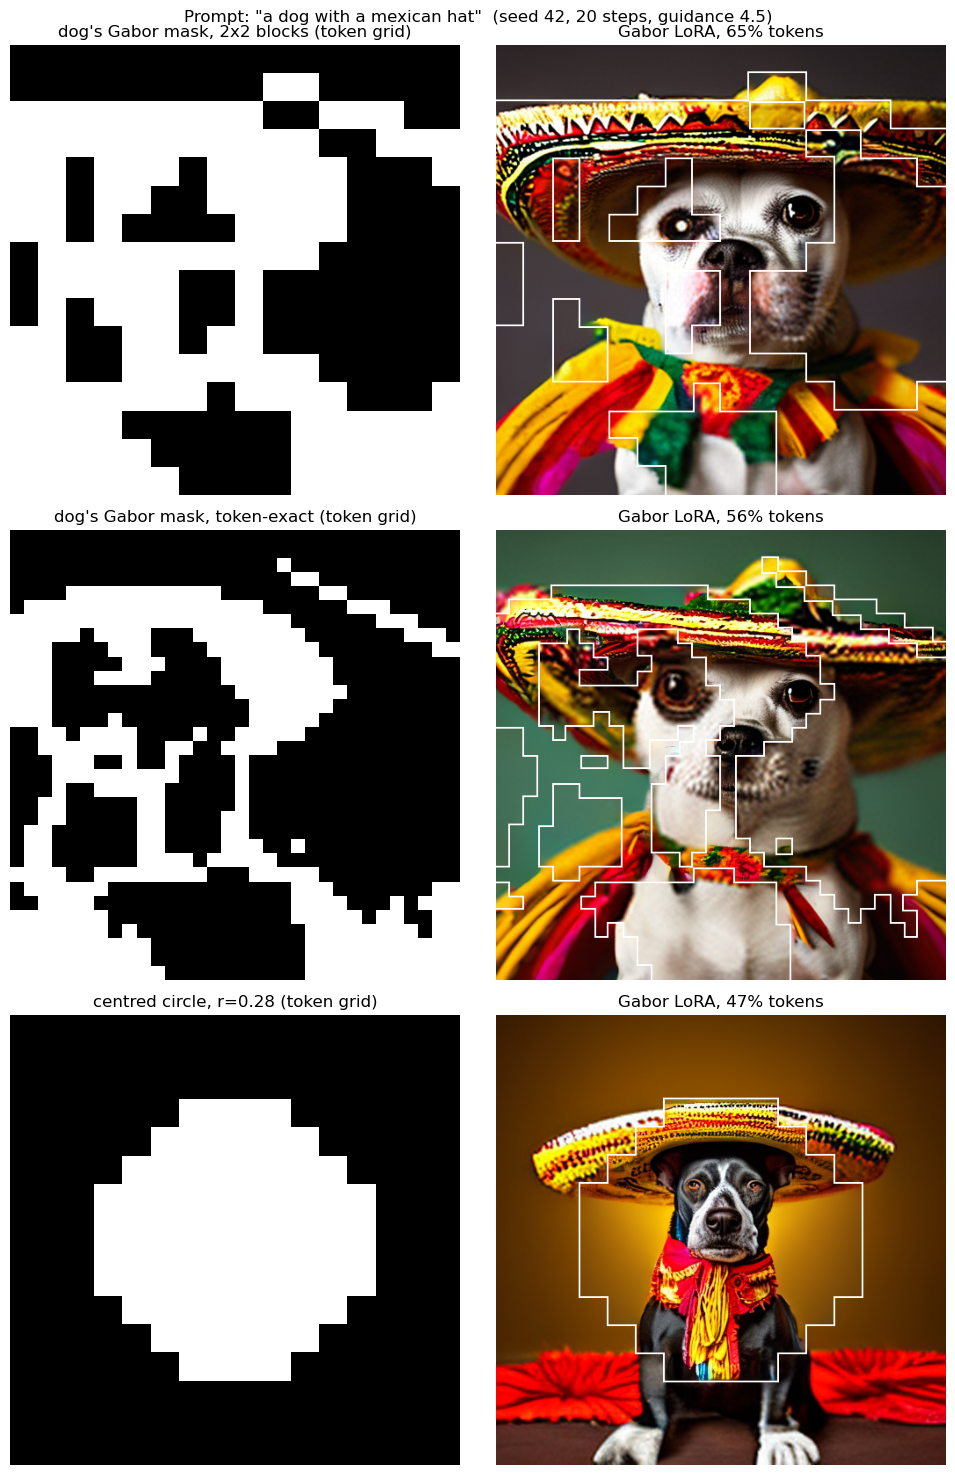

In [55]:
# 6.2) inference with the Gabor LoRA: the dog's Gabor mask vs a centred circle, same prompt and seed
import gc
import time
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from peft import PeftModel
from diffusers import Transformer2DModel, AutoencoderKL, DPMSolverMultistepScheduler
from diffusers.models.embeddings import get_2d_sincos_pos_embed_from_grid
from transformers import T5EncoderModel, T5Tokenizer

I_PROMPT   = "a dog with a mexican hat"
I_SEED     = 42
I_STEPS    = 20
I_GUIDANCE = 4.5
I_MASK_IMG = "./final.png"    # the dog image from section 6; its Gabor mask places the fovea
I_RADIUS   = 0.28             # centred circle, as in section 5.4

# free the training leftovers and earlier sections' models before loading the merged one
g_free(G_EARLIER + ["i_transformer", "i_vae"])


def gabor_token_mask(image, grid=32):
    """(grid, grid) bool mask: each token is fovea if most of its 16x16 pixels pass the threshold."""
    _, bin_mask = generate_gabor_mask(g_resize(image.convert("RGB")),
                                      threshold=0.5, blur_size=51)
    m = F.interpolate(torch.from_numpy(bin_mask)[None, None], size=(grid, grid), mode="area")
    return m[0, 0] > 0.5

# 1. transformer with the Gabor LoRA merged in, VAE, scheduler
i_transformer = Transformer2DModel.from_pretrained(
    model_id, subfolder="transformer", torch_dtype=torch.bfloat16).to(device)
i_transformer = PeftModel.from_pretrained(i_transformer, g_lora_dir).merge_and_unload().eval()
i_vae = AutoencoderKL.from_pretrained(model_id, subfolder="vae", torch_dtype=torch.float16).to(device)
i_sched = DPMSolverMultistepScheduler.from_pretrained(model_id, subfolder="scheduler")

iP, iC, iD = i_transformer.config.patch_size, i_transformer.config.in_channels, i_transformer.inner_dim
i_pe = i_transformer.pos_embed
I_GRID = i_pe.height
I_POS_SCALE = i_pe.base_size / i_pe.height / i_pe.interpolation_scale

# 2. prompt, ordered [unconditional, prompt] - the order the CFG split in i_generate expects
tokenizer = T5Tokenizer.from_pretrained(model_id, subfolder="tokenizer")
text_encoder = T5EncoderModel.from_pretrained(
    model_id, subfolder="text_encoder", torch_dtype=torch.bfloat16).to(device)
with torch.no_grad():
    tok = tokenizer(["", I_PROMPT], padding="max_length", max_length=G_TEXT_LEN,
                    truncation=True, return_tensors="pt").to(device)
    i_embeds = text_encoder(tok.input_ids, attention_mask=tok.attention_mask)[0].to(torch.bfloat16)
    i_text_mask = tok.attention_mask
del text_encoder, tokenizer
gc.collect(); torch.cuda.empty_cache()

# 3. same token layout and forward pass as the training cell (6.1b)
def i_patchify(z):
    B, c, H, W = z.shape
    return z.reshape(B, c, H // iP, iP, W // iP, iP).permute(0, 2, 4, 3, 5, 1) \
            .reshape(B, (H // iP) * (W // iP), iP * iP * c)

def i_unpatchify(tokens, h, w):
    return tokens.reshape(1, h, w, iP, iP, iC).permute(0, 5, 1, 3, 2, 4).reshape(1, iC, h * iP, w * iP)

def i_layout(M, exact=False):
    """exact=False snaps the fovea to whole 2x2 blocks, the way training did. exact=True keeps the
    mask at token resolution: a block that is only partly fovea keeps just its fovea tokens and
    still gets a coarse token, which i_decode uses to fill the rest of that block."""
    h, w = M.shape
    blk = M.reshape(h // 2, 2, w // 2, 2)
    if exact:
        Mb = blk.all(dim=3).all(dim=1)      # only fully-fovea blocks give up their coarse token
    else:
        Mb = blk.any(dim=3).any(dim=1)
        M = Mb.repeat_interleave(2, 0).repeat_interleave(2, 1)
    hi_idx = M.flatten().nonzero().squeeze(1)
    lo_idx = (~Mb).flatten().nonzero().squeeze(1)
    ys, xs = torch.meshgrid(torch.arange(h), torch.arange(w), indexing="ij")
    hi_xy = torch.stack([xs, ys], -1).reshape(-1, 2)[hi_idx].float()
    ys, xs = torch.meshgrid(torch.arange(h // 2), torch.arange(w // 2), indexing="ij")
    lo_xy = torch.stack([xs, ys], -1).reshape(-1, 2)[lo_idx].float() * 2 + 0.5
    xy = torch.cat([hi_xy, lo_xy]) * I_POS_SCALE
    pos = get_2d_sincos_pos_embed_from_grid(iD, xy.T.to(device), output_type="pt").float()[None]
    return dict(M=M, Mb=Mb, hi_idx=hi_idx.to(device), lo_idx=lo_idx.to(device), pos=pos,
                n_hi=len(hi_idx), h=h, w=w, token_ratio=(len(hi_idx) + len(lo_idx)) / (h * w))

def i_circle(radius, grid):
    ys, xs = torch.meshgrid(torch.arange(grid), torch.arange(grid), indexing="ij")
    return ((ys + 0.5) / grid - 0.5) ** 2 + ((xs + 0.5) / grid - 0.5) ** 2 < radius ** 2

@torch.no_grad()
def i_forward(x, t, layout):
    B = x.shape[0]
    W_in = i_pe.proj.weight.permute(0, 2, 3, 1).reshape(iD, iP * iP * iC)
    h = F.linear(x, W_in, i_pe.proj.bias) + layout["pos"].to(x.dtype)
    t_emb, t_raw = i_transformer.adaln_single(t.expand(B), {"resolution": None, "aspect_ratio": None},
                                              batch_size=B, hidden_dtype=h.dtype)
    enc = i_transformer.caption_projection(i_embeds).view(B, -1, iD)
    enc_bias = ((1 - i_text_mask.to(h.dtype)) * -10000.0).unsqueeze(1)
    for block in i_transformer.transformer_blocks:
        h = block(h, attention_mask=None, encoder_hidden_states=enc, encoder_attention_mask=enc_bias,
                  timestep=t_emb, cross_attention_kwargs=None, class_labels=None)
    shift, scale = (i_transformer.scale_shift_table[None] + t_raw[:, None]).chunk(2, dim=1)
    out = i_transformer.proj_out(i_transformer.norm_out(h) * (1 + scale) + shift)
    return out.reshape(B, -1, iP * iP, i_transformer.out_channels)[..., :iC].reshape(B, -1, iP * iP * iC)

# 4. denoising loop (latents kept in fp32, the model runs in bf16)
@torch.no_grad()
def i_generate(layout, seed):
    i_sched.set_timesteps(I_STEPS)
    g = torch.Generator(device=device).manual_seed(seed)
    z = torch.randn((1, iC, layout["h"] * iP, layout["w"] * iP), generator=g, device=device)
    z_lo = F.avg_pool2d(z, 2) * 2                     # unit-variance noise on the coarse grid
    x = torch.cat([i_patchify(z)[:, layout["hi_idx"]], i_patchify(z_lo)[:, layout["lo_idx"]]], dim=1)
    x = x * i_sched.init_noise_sigma
    for t in tqdm(i_sched.timesteps, leave=False):
        x_in = i_sched.scale_model_input(torch.cat([x] * 2), t).to(torch.bfloat16)
        eps_uncond, eps_text = i_forward(x_in, t.to(device), layout).float().chunk(2)
        x = i_sched.step(eps_uncond + I_GUIDANCE * (eps_text - eps_uncond), t, x).prev_sample
    return x

# 5. split -> decode each part -> upsample the periphery -> blend (paper Eq. 5-7).
#    No amplitude calibration: this LoRA was trained on E(Down(x)), so its periphery is a real latent.
@torch.no_grad()
def i_decode(x, layout):
    h, w, n_hi = layout["h"], layout["w"], layout["n_hi"]
    hi = torch.zeros(1, h * w, iP * iP * iC, device=device)
    lo = torch.zeros(1, (h // 2) * (w // 2), iP * iP * iC, device=device)
    hi[:, layout["hi_idx"]] = x[:, :n_hi]
    lo[:, layout["lo_idx"]] = x[:, n_hi:]
    z_hi, z_lo = i_unpatchify(hi, h, w), i_unpatchify(lo, h // 2, w // 2)

    # fill each grid's empty part from the other, so the decoder sees no zeros near the seam
    m_hi = layout["M"].repeat_interleave(iP, 0).repeat_interleave(iP, 1).to(device)
    m_lo = layout["Mb"].repeat_interleave(iP, 0).repeat_interleave(iP, 1).to(device)
    z_lo = torch.where(m_lo, F.avg_pool2d(z_hi, 2), z_lo)
    z_hi = torch.where(m_hi, z_hi, F.interpolate(z_lo, scale_factor=2, mode="bilinear", align_corners=False))

    sf = i_vae.config.scaling_factor
    img_hi = i_vae.decode((z_hi / sf).half()).sample.float()
    img_lo = i_vae.decode((z_lo / sf).half()).sample.float()
    img_lo_up = F.interpolate(img_lo, scale_factor=2, mode="bicubic")
    m_px = layout["M"].float().repeat_interleave(iP * 8, 0).repeat_interleave(iP * 8, 1).to(device)
    img = m_px * img_hi + (1 - m_px) * img_lo_up
    img = ((img / 2 + 0.5).clamp(0, 1)[0].permute(1, 2, 0).cpu().numpy() * 255).round().astype("uint8")
    return Image.fromarray(img)

def i_border(pil_img, M, color=(255, 255, 255)):
    """White outline around the high-res region, like the figures in the paper."""
    m = F.interpolate(M.float()[None, None], size=pil_img.size[::-1], mode="nearest")
    ring = (F.max_pool2d(m, 5, stride=1, padding=2) - m)[0, 0] > 0
    arr = np.array(pil_img)
    arr[ring.numpy()] = color
    return Image.fromarray(arr)

# 6. the two masks, same prompt and seed
print(f"Gabor mask from '{I_MASK_IMG}' with threshold={G_THRESHOLD}, blur={G_BLUR}")
i_gabor_M = gabor_token_mask(Image.open(I_MASK_IMG), grid=I_GRID)
i_masks = {
    "gabor_dog":       ("dog's Gabor mask, 2x2 blocks", i_gabor_M, False),
    "gabor_dog_exact": ("dog's Gabor mask, token-exact", i_gabor_M, True),
    "center":          (f"centred circle, r={I_RADIUS}", i_circle(I_RADIUS, I_GRID), False),
}

fig, axs = plt.subplots(len(i_masks), 2, figsize=(10, 5 * len(i_masks)))
for row, (key, (name, M, exact)) in enumerate(i_masks.items()):
    layout = i_layout(M, exact=exact)
    torch.cuda.synchronize(); t0 = time.time()
    img = i_decode(i_generate(layout, I_SEED), layout)
    torch.cuda.synchronize(); dt = time.time() - t0
    img.save(f"gabor_lora_{key}.png")
    print(f"{name}: {layout['token_ratio']:.0%} tokens, {dt:.1f}s -> gabor_lora_{key}.png")

    axs[row, 0].imshow(layout["M"], cmap="gray", vmin=0, vmax=1)
    axs[row, 0].set_title(f"{name} (token grid)")
    axs[row, 1].imshow(i_border(img, layout["M"]))
    axs[row, 1].set_title(f"Gabor LoRA, {layout['token_ratio']:.0%} tokens")
for ax in axs.flat:
    ax.axis("off")
plt.suptitle(f'Prompt: "{I_PROMPT}"  (seed {I_SEED}, {I_STEPS} steps, guidance {I_GUIDANCE})')
plt.tight_layout()
plt.show()